<a href="https://colab.research.google.com/github/ogunsolahabib/realtor-cnn/blob/main/Pred_Neural_Networks_Project_Habib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# If running in a fresh environment, you may need installs
import sys
!{sys.executable} -m pip install numpy scikit-learn matplotlib pandas kagglehub seaborn torch --quiet


In [ ]:
# Core imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import kagglehub


In [ ]:
# Kaggle real estate dataset
path = kagglehub.dataset_download("ahmedshahriarsakib/usa-real-estate-dataset")

csv_file_path = os.path.join(path, "realtor-data.zip.csv")
df = pd.read_csv(csv_file_path)

print("Column data types:")
print(df.dtypes)
print(f"\nOriginal data size: {df.shape[0]} rows, {df.shape[1]} columns")


Column data types:
brokered_by       float64
status             object
price             float64
bed               float64
bath              float64
acre_lot          float64
street            float64
city               object
state              object
zip_code          float64
house_size        float64
prev_sold_date     object
dtype: object

Original data size: 2226382 rows, 12 columns


In [ ]:
# Convert date to numeric and drop original date column
if "prev_sold_date" in df.columns:
    df["prev_sold_date_numeric"] = pd.to_datetime(
        df["prev_sold_date"], errors="coerce"
    ).astype("int64") // 10**9
    df = df.drop(columns=["prev_sold_date"])

# X = all non-price, non-price_class columns
FEATURE_COLUMNS = [col for col in df.columns if col not in ["price", "price_class"]]
TARGET_COLUMN = "price"

print("Feature columns (X):", FEATURE_COLUMNS)
print("Number of original features m:", len(FEATURE_COLUMNS))

numerical_cols = df[FEATURE_COLUMNS].select_dtypes(include=np.number).columns.tolist()
categorical_cols = df[FEATURE_COLUMNS].select_dtypes(include="object").columns.tolist()
print("\nNumerical features:", numerical_cols)
print("Categorical features:", categorical_cols)

df_processed = df[FEATURE_COLUMNS].copy()

# Label‑encode categoricals
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_processed[col] = df_processed[col].fillna("missing")
    df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    label_encoders[col] = le

X = df_processed.values
y_price = df[TARGET_COLUMN].values

# Impute and scale X
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_processed = scaler.fit_transform(X_imputed)

print("Final X_processed shape:", X_processed.shape)
m = X_processed.shape[1]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("m =", m, "device =", device)


Feature columns (X): ['brokered_by', 'status', 'bed', 'bath', 'acre_lot', 'street', 'city', 'state', 'zip_code', 'house_size', 'prev_sold_date_numeric']
Number of original features m: 11

Numerical features: ['brokered_by', 'bed', 'bath', 'acre_lot', 'street', 'zip_code', 'house_size', 'prev_sold_date_numeric']
Categorical features: ['status', 'city', 'state']
Final X_processed shape: (2226382, 11)
m = 11 device = cpu



=== PCA SUMMARY (Part I – m*) ===
Total components: 11
Components for ≥80% variance (m*): 8
Variance preserved at m*: 84.35%

Principal Components variance table (first 12 PCs):
 PC  Variance (%)  Cumulative (%)
  1        14.737          14.737
  2        14.378          29.115
  3        10.262          39.377
  4         9.191          48.568
  5         9.091          57.659
  6         9.089          66.748
  7         8.946          75.694
  8         8.657          84.352
  9         7.806          92.157
 10         4.070          96.227
 11         3.773         100.000


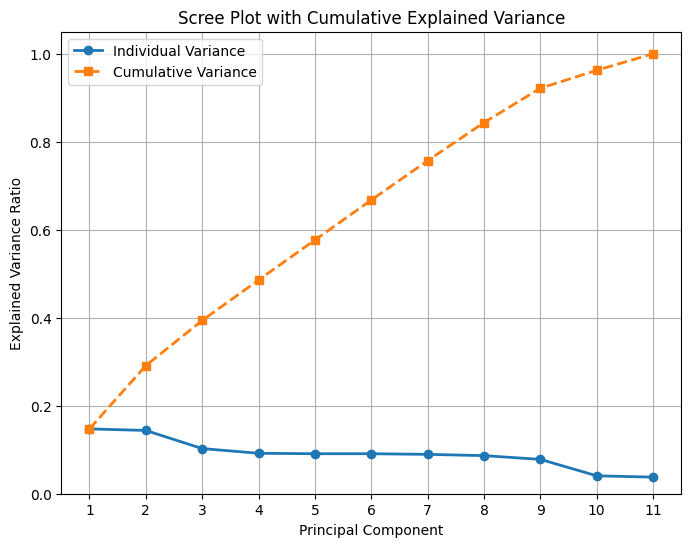

In [ ]:
pca_full = PCA()
X_pca = pca_full.fit_transform(X_processed)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

m_star = np.argmax(cumulative_var >= 0.80) + 1

print("\n=== PCA SUMMARY (Part I – m*) ===")
print("Total components:", len(explained_var))
print("Components for ≥80% variance (m*):", m_star)
print(f"Variance preserved at m*: {cumulative_var[m_star-1]*100:.2f}%")

var_table = pd.DataFrame({
    "PC": np.arange(1, len(explained_var) + 1),
    "Variance (%)": explained_var * 100,
    "Cumulative (%)": cumulative_var * 100,
})
print("\nPrincipal Components variance table (first 12 PCs):")
print(var_table.head(12).to_string(index=False, float_format="%.3f"))

plt.figure(figsize=(8, 6))
components = np.arange(1, len(explained_var) + 1)
plt.plot(components, explained_var, "o-", linewidth=2, label="Individual Variance")
plt.plot(components, cumulative_var, "s--", linewidth=2, label="Cumulative Variance")
plt.title("Scree Plot with Cumulative Explained Variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
pca_reduced = PCA(n_components=m_star)
X_pca_reduced = pca_reduced.fit_transform(X_processed)          # (n, m*)
X_reconstructed_reduced = pca_reduced.inverse_transform(X_pca_reduced)
X_reconstructed_full = pca_full.inverse_transform(X_pca)

mse_full = np.mean((X_processed - X_reconstructed_full) ** 2)
mse_reduced = np.mean((X_processed - X_reconstructed_reduced) ** 2)

print("\n=== Reconstruction quality ===")
print(f"MSE using all {m} PCs: {mse_full:.10f}")
print(f"MSE using m*={m_star} PCs: {mse_reduced:.6f}")
print(f"Dimensionality reduction in PC space: {m} → {m_star} PCs")

# X_pc_for_nn = X_pca_reduced.copy() # former, changing to what the workflow says
X_pc_for_nn = X_reconstructed_reduced.copy()


print("X_pc_for_nn shape:", X_pc_for_nn.shape)



=== Reconstruction quality ===
MSE using all 11 PCs: 0.0000000000
MSE using m*=8 PCs: 0.156485
Dimensionality reduction in PC space: 11 → 8 PCs
X_pc_for_nn shape: (2226382, 11)


In [ ]:
# ## Part I – Dimensionality Reduction (Summary)

# - Original feature dimension: m = 11.
# - PCA on standardized X gives m* = 8 components to reach ≥80% variance (≈84.35%).
# - X is transformed to PC space (shape n × 8); reconstruction X̂ using 8 PCs keeps reconstruction MSE small compared to using all 11 PCs.
# - From here on, all modeling (classification network) uses the reduced PC representation `X_pc_for_nn` as the input feature matrix.


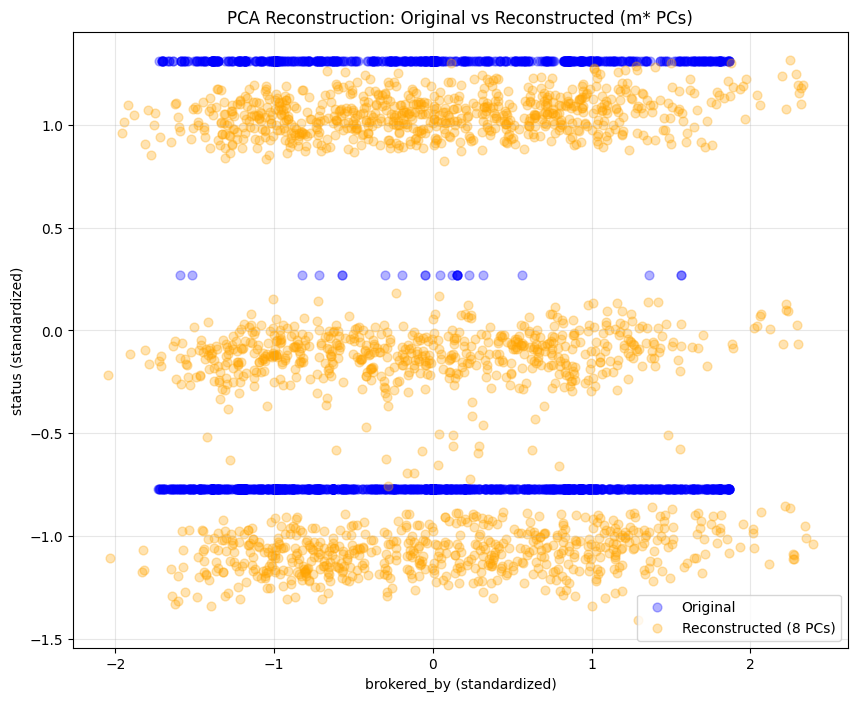

In [ ]:
n_plot = min(2000, X_processed.shape[0])
idx = np.random.choice(X_processed.shape[0], n_plot, replace=False)
i1, i2 = 0, 1

plt.figure(figsize=(10, 8))
plt.scatter(X_processed[idx, i1], X_processed[idx, i2],
            alpha=0.3, s=40, label="Original", c="blue")
plt.scatter(X_reconstructed_reduced[idx, i1], X_reconstructed_reduced[idx, i2],
            alpha=0.3, s=40, label=f"Reconstructed ({m_star} PCs)", c="orange")
plt.xlabel(f"{FEATURE_COLUMNS[i1]} (standardized)")
plt.ylabel(f"{FEATURE_COLUMNS[i2]} (standardized)")
plt.title("PCA Reconstruction: Original vs Reconstructed (m* PCs)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


=== PRICE CLASS SUMMARY (Part II) ===
Minimum price: 0.0
Maximum price: 2147483600.0

Price thresholds (USD):
Low:    below 165,000.00
Medium: 165,000.00 to 325,000.00
High:   325,000.00 to 550,000.00
Very High: above 550,000.00

Class counts:
price_class
Medium       560881
Low          559279
High         555644
Very High    549037
Name: count, dtype: int64


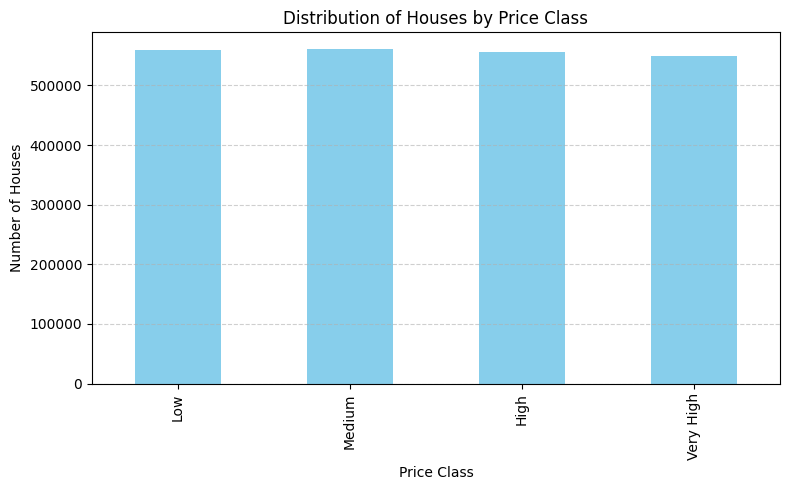

In [ ]:
df["price_class"] = pd.qcut(
    df["price"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

min_price = df["price"].min()
max_price = df["price"].max()
quantiles = df["price"].quantile([0.25, 0.50, 0.75])

print("=== PRICE CLASS SUMMARY (Part II) ===")
print("Minimum price:", min_price)
print("Maximum price:", max_price)
print("\nPrice thresholds (USD):")
print(f"Low:    below {quantiles[0.25]:,.2f}")
print(f"Medium: {quantiles[0.25]:,.2f} to {quantiles[0.50]:,.2f}")
print(f"High:   {quantiles[0.50]:,.2f} to {quantiles[0.75]:,.2f}")
print(f"Very High: above {quantiles[0.75]:,.2f}")

class_counts = df["price_class"].value_counts()
print("\nClass counts:")
print(class_counts)

plt.figure(figsize=(8, 5))
class_counts.sort_index().plot(kind="bar", color="skyblue")
plt.title("Distribution of Houses by Price Class")
plt.xlabel("Price Class")
plt.ylabel("Number of Houses")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [ ]:
mask = df["price_class"].notna()

df_filtered = df[mask].copy()
X_pc_filtered = X_pc_for_nn[mask]
y_classes = df_filtered["price_class"].values

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_classes)
num_classes = len(encoder.classes_)

print("Encoded classes:", list(encoder.classes_))
print("X_pc_filtered shape:", X_pc_filtered.shape)
print("y_encoded shape:", y_encoded.shape)
print("Number of classes C:", num_classes)


Encoded classes: ['High', 'Low', 'Medium', 'Very High']
X_pc_filtered shape: (2224841, 11)
y_encoded shape: (2224841,)
Number of classes C: 4


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pc_filtered,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

train_ds = torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor)
test_ds = torch.utils.data.TensorDataset(X_test_tensor, y_test_tensor)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=1024, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=4096, shuffle=False)


Train shape: (1779872, 11)
Test shape: (444969, 11)


In [ ]:
# Setup NN comparison list
nn_comparison_list = []

In [ ]:
class SimpleNet(nn.Module):
    """
    Initial network: (m, 8, 4, C).
    Input: m principal components.
    Output: C logits, one per price class (for CrossEntropyLoss).
    """
    def __init__(self, m_star, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(m_star, 8)
        self.fc2 = nn.Linear(8, 4)
        self.fc3 = nn.Linear(4, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

m_input = X_pc_filtered.shape[1]    # = m_star
model_init = SimpleNet(m_input, num_classes).to(device)
print(model_init)


SimpleNet(
  (fc1): Linear(in_features=11, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=4, bias=True)
  (fc3): Linear(in_features=4, out_features=4, bias=True)
)


In [ ]:
# Cell [13] - Train SimpleNet with immediate visualization
from scipy.ndimage import uniform_filter1d

n_epochs = 20
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_init.parameters(), lr=0.005)

# Storage for iteration-level data
simplenet_iteration_data = {
    'loss_per_iteration': [],
    'mse_per_iteration': [],
    'per_class_mse_per_iteration': [],
    'model_name': 'SimpleNet (11,8,4,4)'
}

per_class_mse_history = {cls: [] for cls in encoder.classes_}
overall_mse_history = []

print(f"Training initial SimpleNet for {n_epochs} epochs...")
for epoch in range(n_epochs):
    model_init.train()
    total_loss = 0.0

    for Xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model_init(Xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        # Save iteration data
        simplenet_iteration_data['loss_per_iteration'].append(loss.item())

        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            errors = (preds - yb).float() ** 2
            batch_mse = errors.mean().item()
            simplenet_iteration_data['mse_per_iteration'].append(batch_mse)

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (yb == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls
            simplenet_iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

        total_loss += loss.item()

    # Evaluate MSE on test set
    model_init.eval()
    all_true = []
    all_pred = []
    with torch.no_grad():
        for Xb, yb in test_loader:
            logits = model_init(Xb)
            preds = torch.argmax(logits, dim=1)
            all_true.append(yb.cpu().numpy())
            all_pred.append(preds.cpu().numpy())

    all_true = np.concatenate(all_true)
    all_pred = np.concatenate(all_pred)
    errors = (all_pred - all_true) ** 2
    overall_mse = errors.mean()
    overall_mse_history.append(overall_mse)

    for idx, cls_name in enumerate(encoder.classes_):
        mask_cls = (all_true == idx)
        mse_cls = errors[mask_cls].mean() if mask_cls.any() else np.nan
        per_class_mse_history[cls_name].append(mse_cls)

    avg_loss_epoch = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{n_epochs} - train loss {avg_loss_epoch:.4f}, "
          f"test overall MSE {overall_mse:.4f}")

print("✓ SimpleNet training complete\n")


final_mse_simple = np.mean(simplenet_iteration_data['mse_per_iteration'][-100:])
print(f"\n📊 SimpleNet Final MSE: {final_mse_simple:.4f}")
print("💡 Observation: High class has highest MSE")
print("💡 Decision: Try expanded architecture for more capacity\n")





Training initial SimpleNet for 20 epochs...
Epoch 1/20 - train loss 1.1827, test overall MSE 1.9487
Epoch 2/20 - train loss 1.1472, test overall MSE 1.9108
Epoch 3/20 - train loss 1.1358, test overall MSE 1.8867
Epoch 4/20 - train loss 1.1122, test overall MSE 1.8828
Epoch 5/20 - train loss 1.0940, test overall MSE 1.8690
Epoch 6/20 - train loss 1.0909, test overall MSE 1.8734
Epoch 7/20 - train loss 1.0883, test overall MSE 1.8147
Epoch 8/20 - train loss 1.0869, test overall MSE 1.8904
Epoch 9/20 - train loss 1.0856, test overall MSE 1.8681
Epoch 10/20 - train loss 1.0824, test overall MSE 1.8338
Epoch 11/20 - train loss 1.0805, test overall MSE 1.8292
Epoch 12/20 - train loss 1.0788, test overall MSE 1.8305
Epoch 13/20 - train loss 1.0781, test overall MSE 1.8362
Epoch 14/20 - train loss 1.0776, test overall MSE 1.7870
Epoch 15/20 - train loss 1.0775, test overall MSE 1.8292
Epoch 16/20 - train loss 1.0773, test overall MSE 1.8446
Epoch 17/20 - train loss 1.0772, test overall MSE 1.8

PART III: INITIAL NETWORK (SimpleNet) - ANALYSIS


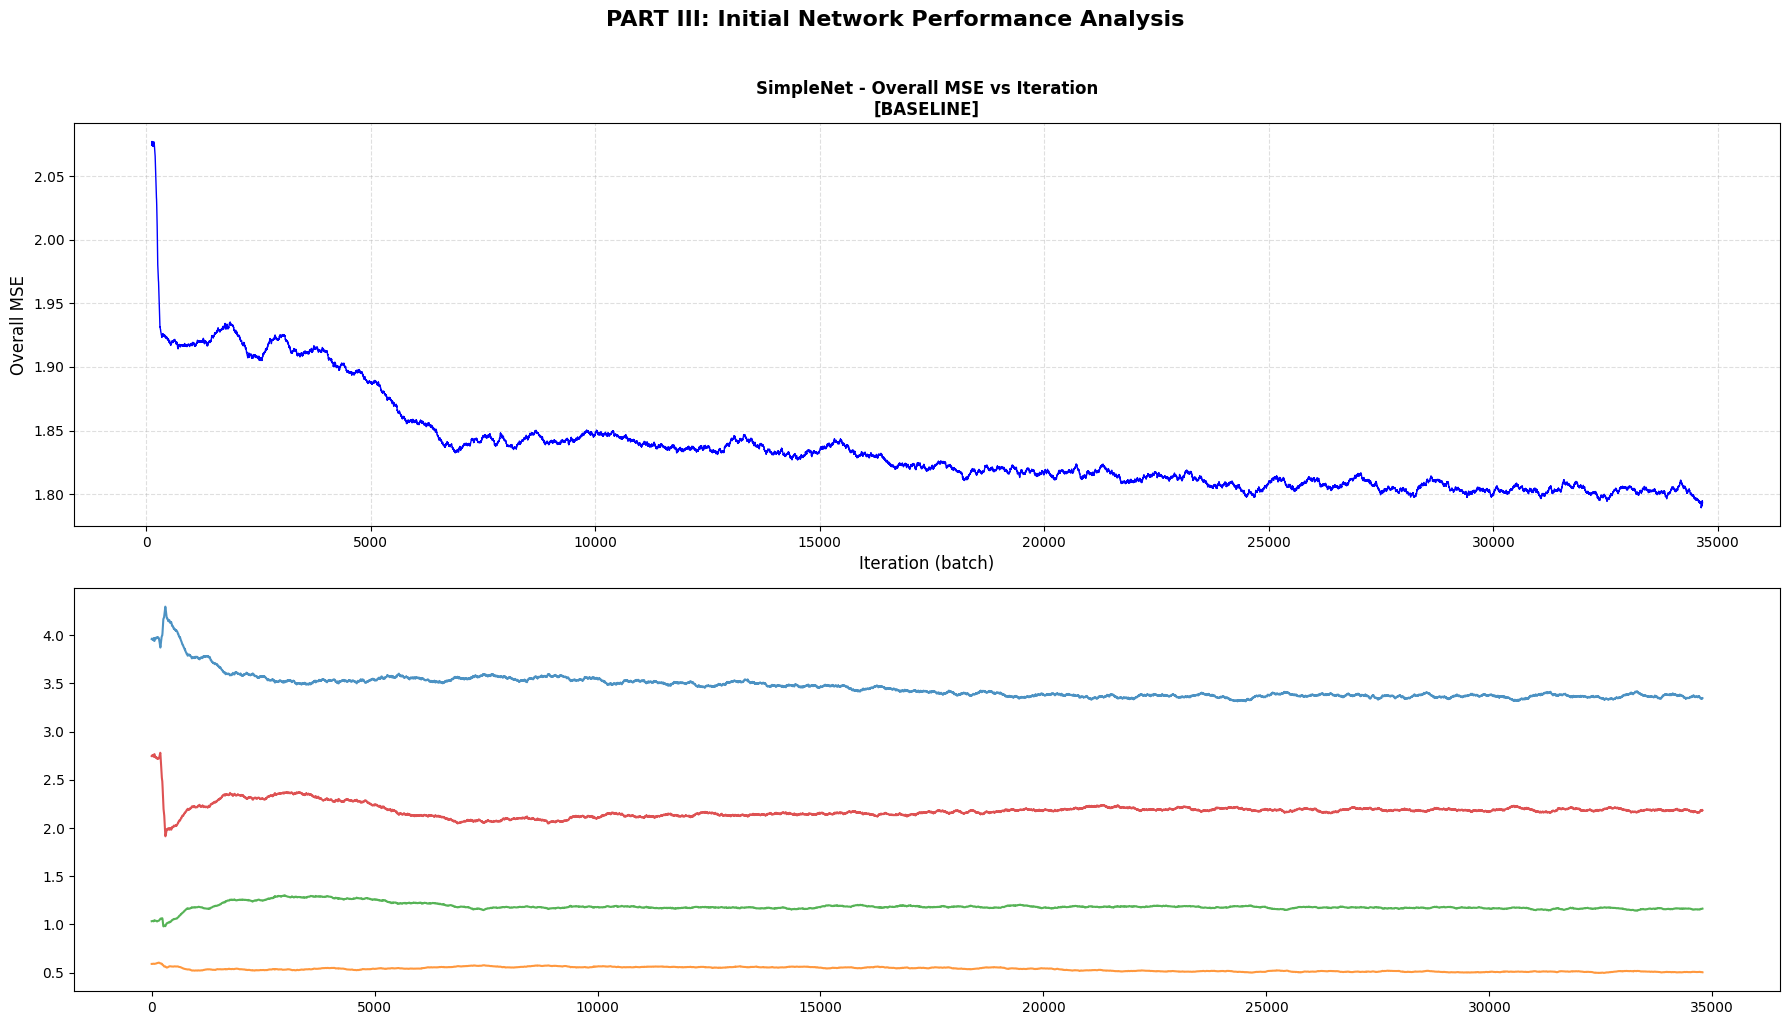

In [ ]:

# ============================================================================
# IMMEDIATE PLOT AFTER SIMPLENET TRAINING
# ============================================================================
print("="*80)
print("PART III: INITIAL NETWORK (SimpleNet) - ANALYSIS")
print("="*80)

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

iterations = np.arange(1, len(simplenet_iteration_data['loss_per_iteration']) + 1)


# Loss
# axes[0].plot(iterations, simplenet_iteration_data['loss_per_iteration'],
#              color='blue', alpha=0.8, linewidth=1.5)
# axes[0].set_xlabel("Iteration (batch)")
# axes[0].set_ylabel("Cross-Entropy Loss")
# axes[0].set_title("SimpleNet (11,8,4,4) - Loss vs Iteration\n[BASELINE]",
#                   fontweight='bold')
# axes[0].grid(True, linestyle="--", alpha=0.4)

# MSE
# axes[1].plot(iterations, simplenet_iteration_data['mse_per_iteration'],
#              color='blue', alpha=0.8, linewidth=1.5)
# axes[1].set_xlabel("Iteration (batch)")
# axes[1].set_ylabel("Overall MSE")
# axes[1].set_title("SimpleNet - Overall MSE vs Iteration\n[BASELINE]",
#                   fontweight='bold')
# axes[1].grid(True, linestyle="--", alpha=0.4)




# # MSE - Raw and Smoothed
# # axes[1].plot(iterations, simplenet_iteration_data['mse_per_iteration'],
# #              color='lightblue', alpha=0.3, linewidth=0.5, label='Raw')  # Faint raw data

# # Smooth
# mse_smoothed = uniform_filter1d(simplenet_iteration_data['mse_per_iteration'], size=window_size)
# axes[1].plot(iterations, mse_smoothed,
#              color='blue', alpha=0.9, linewidth=2.5, label='Smoothed')

# axes[1].set_xlabel("Iteration (batch)", fontsize=12)
# axes[1].set_ylabel("Overall MSE", fontsize=12)
# axes[1].set_title("SimpleNet - Overall MSE vs Iteration\n[BASELINE]", fontweight='bold')
# axes[1].legend()
# axes[1].grid(True, linestyle="--", alpha=0.4)



window_size = 500  # Increase for smoother curve

# DON'T plot raw data at all
# axes[1].plot(iterations, simplenet_iteration_data['mse_per_iteration'], ...)  # REMOVE THIS

# ONLY plot smoothed
mse_smoothed = uniform_filter1d(simplenet_iteration_data['mse_per_iteration'], size=window_size)
axes[0].plot(uniform_filter1d(iterations, size= window_size), mse_smoothed,
             color='blue', alpha=1.0, linewidth=1)

axes[0].set_xlabel("Iteration (batch)", fontsize=12)
axes[0].set_ylabel("Overall MSE", fontsize=12)
axes[0].set_title("SimpleNet - Overall MSE vs Iteration\n[BASELINE]", fontweight='bold')
axes[0].grid(True, linestyle="--", alpha=0.4)


# Per-class MSE
per_class_simple = {cls: [] for cls in encoder.classes_}
for d in simplenet_iteration_data['per_class_mse_per_iteration']:
    for cls_name in encoder.classes_:
        per_class_simple[cls_name].append(d[cls_name])

for cls_name in encoder.classes_:
    axes[1].plot(iterations, uniform_filter1d(per_class_simple[cls_name], size=window_size),
                label=cls_name, alpha=0.8, linewidth=1.5)

plt.suptitle("PART III: Initial Network Performance Analysis",
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
# plt.savefig("01_simplenet_baseline.png", dpi=150, bbox_inches='tight')
plt.show()



In [ ]:

def filtered_1d(data, prop, window_size=500):
    return uniform_filter1d(data[prop], size = window_size)

In [ ]:
def nn_comparison_plot_data(network_dict):
    return {
"name": network_dict["model_name"],
"iterations":np.arange(1, len(network_dict['loss_per_iteration']) + 1),
"loss_per_iteration": filtered_1d(network_dict, 'loss_per_iteration'),
"mse_per_iteration":filtered_1d(network_dict, 'mse_per_iteration')
                       }

In [ ]:
nn_comparison_colors=["blue", "green", "red", "cyan", "magenta"]

In [ ]:
nn_comparison_list.append(nn_comparison_plot_data(simplenet_iteration_data))


In [ ]:
# Re-instantiate the initial network
model_init_iter = SimpleNet(m_input, num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_init_iter.parameters(), lr=0.005)

n_epochs_iter = 10  # keep small so iteration plots are readable
loss_per_iteration = []              # overall loss per batch
per_class_mse_per_iteration = []     # list of dicts; one per batch

print(f"Training initial SimpleNet for {n_epochs_iter} epochs with iteration-level tracking...")

for epoch in range(n_epochs_iter):
    model_init_iter.train()
    for Xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model_init_iter(Xb.to(device))
        loss = criterion(logits, yb.to(device))
        loss.backward()
        optimizer.step()

        # ---- record loss per iteration (batch) ----
        loss_per_iteration.append(loss.item())

        # ---- compute per-class MSE on this batch ----
        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            y_true_batch = yb.to(device)
            errors = (preds - y_true_batch).float() ** 2

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (y_true_batch == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls

            per_class_mse_per_iteration.append(class_mse_dict)

print("Training complete (iteration-level stats recorded).")


Training initial SimpleNet for 10 epochs with iteration-level tracking...
Training complete (iteration-level stats recorded).


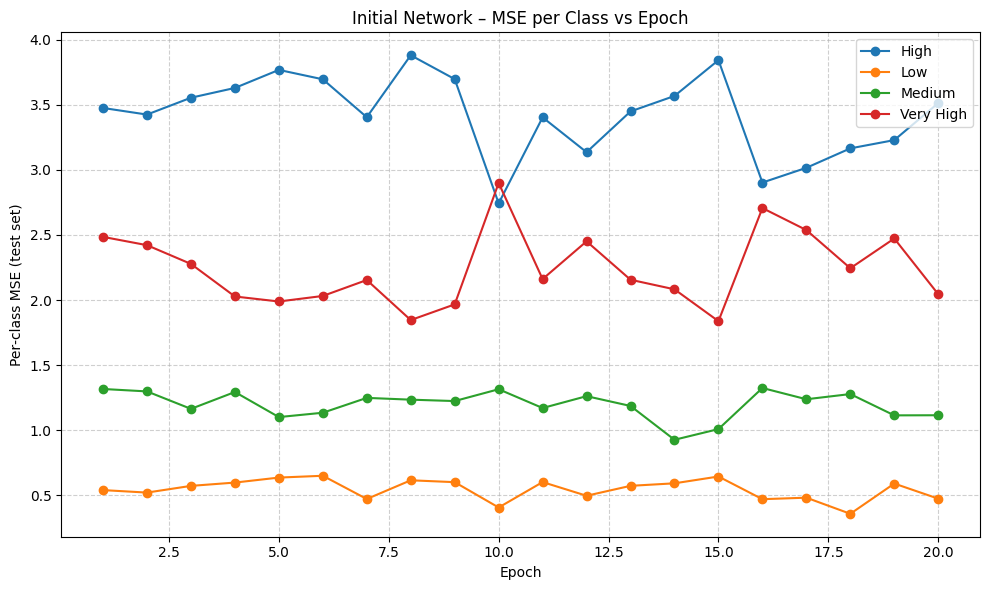

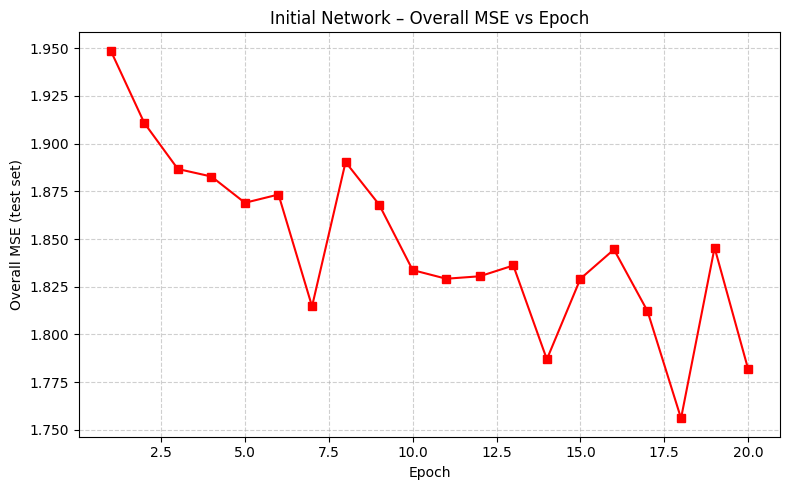

In [ ]:
epochs = np.arange(1, n_epochs + 1)

plt.figure(figsize=(10, 6))
for cls_name, history in per_class_mse_history.items():
    plt.plot(epochs, history, marker="o", label=cls_name)
plt.xlabel("Epoch")
plt.ylabel("Per‑class MSE (test set)")
plt.title("Initial Network – MSE per Class vs Epoch")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, overall_mse_history, marker="s", color="red")
plt.xlabel("Epoch")
plt.ylabel("Overall MSE (test set)")
plt.title("Initial Network – Overall MSE vs Epoch")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [ ]:
# iterations = np.arange(1, len(loss_per_iteration) + 1)

# plt.figure(figsize=(10, 6))
# plt.plot(iterations, loss_per_iteration, color="blue", alpha=0.8)
# plt.xlabel("Iteration (batch)")
# plt.ylabel("Cross-Entropy Loss")
# plt.title("Initial Network – Loss vs Iteration (Part III ii)")
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.tight_layout()
# plt.show()


In [ ]:
def train_once_simple(X_all, y_all, m_input, num_classes, n_epochs_trial=10, seed=None):
    if seed is not None:
        np.random.seed(seed)
        torch.manual_seed(seed)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all,
        y_all,
        test_size=0.2,
        random_state=seed,
        stratify=y_all
    )

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    X_te_t = torch.tensor(X_te, dtype=torch.float32).to(device)
    y_te_t = torch.tensor(y_te, dtype=torch.long).to(device)

    train_ds_t = torch.utils.data.TensorDataset(X_tr_t, y_tr_t)
    test_ds_t = torch.utils.data.TensorDataset(X_te_t, y_te_t)
    train_loader_t = torch.utils.data.DataLoader(train_ds_t, batch_size=1024, shuffle=True)
    test_loader_t = torch.utils.data.DataLoader(test_ds_t, batch_size=4096, shuffle=False)

    model_t = SimpleNet(m_input, num_classes).to(device)
    opt_t = optim.Adam(model_t.parameters(), lr=0.005)
    crit_t = nn.CrossEntropyLoss()

    overall_mse_list = []
    per_class_mse_lists = {cls: [] for cls in encoder.classes_}

    for ep in range(n_epochs_trial):
        model_t.train()
        for Xb, yb in train_loader_t:
            opt_t.zero_grad()
            logits = model_t(Xb)
            loss = crit_t(logits, yb)
            loss.backward()
            opt_t.step()

        model_t.eval()
        all_true = []
        all_pred = []
        with torch.no_grad():
            for Xb, yb in test_loader_t:
                logits = model_t(Xb)
                preds = torch.argmax(logits, dim=1)
                all_true.append(yb.cpu().numpy())
                all_pred.append(preds.cpu().numpy())

        all_true = np.concatenate(all_true)
        all_pred = np.concatenate(all_pred)
        errors = (all_pred - all_true) ** 2
        overall_mse_list.append(errors.mean())

        for idx, cls_name in enumerate(encoder.classes_):
            mask_cls = (all_true == idx)
            mse_cls = errors[mask_cls].mean() if mask_cls.any() else np.nan
            per_class_mse_lists[cls_name].append(mse_cls)

    return np.array(overall_mse_list), {k: np.array(v) for k, v in per_class_mse_lists.items()}


Running M = 10 random 80–20 trials with SimpleNet...


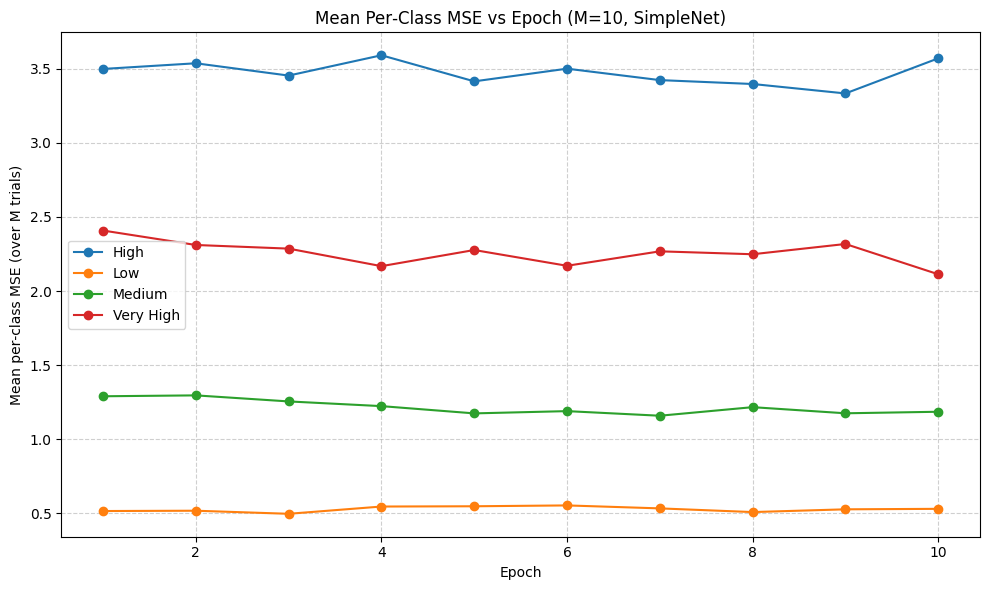

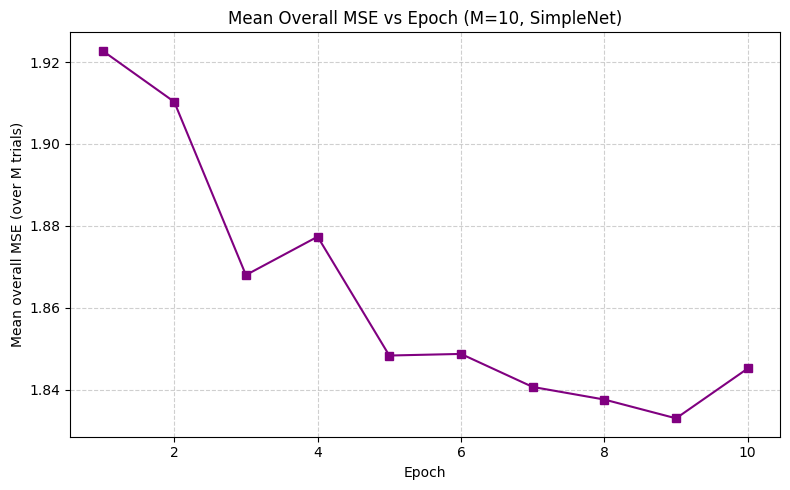

Mean overall MSE (last epoch): 1.8451444932118866


In [ ]:
# M-trials cross validation
M = 10
n_epochs_trial = 10

mean_overall_mse = np.zeros(n_epochs_trial)
mean_per_class_mse = {cls: np.zeros(n_epochs_trial) for cls in encoder.classes_}

print(f"Running M = {M} random 80–20 trials with SimpleNet...")

for trial in range(M):
    overall_mse_trial, per_class_mse_trial = train_once_simple(
        X_pc_filtered, y_encoded, m_input, num_classes,
        n_epochs_trial=n_epochs_trial,
        seed=100 + trial
    )

    mean_overall_mse += overall_mse_trial / M
    for cls_name in encoder.classes_:
        mean_per_class_mse[cls_name] += per_class_mse_trial[cls_name] / M

epochs_t = np.arange(1, n_epochs_trial + 1)

plt.figure(figsize=(10, 6))
for cls_name in encoder.classes_:
    plt.plot(epochs_t,
             mean_per_class_mse[cls_name],
             marker="o",
             label=cls_name)
plt.xlabel("Epoch")
plt.ylabel("Mean per‑class MSE (over M trials)")
plt.title(f"Mean Per‑Class MSE vs Epoch (M={M}, SimpleNet)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_t, mean_overall_mse, marker="s", color="purple")
plt.xlabel("Epoch")
plt.ylabel("Mean overall MSE (over M trials)")
plt.title(f"Mean Overall MSE vs Epoch (M={M}, SimpleNet)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print("Mean overall MSE (last epoch):", mean_overall_mse[-1])


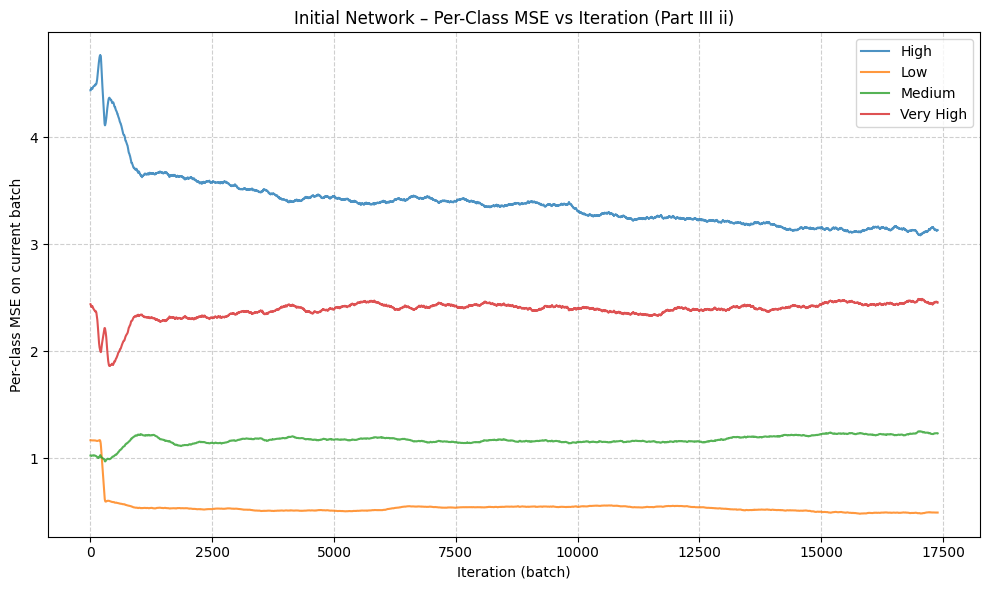

In [ ]:
# Convert list of dicts to arrays per class
per_class_mse_iter = {cls: [] for cls in encoder.classes_}
for d in per_class_mse_per_iteration:
    for cls_name in encoder.classes_:
        per_class_mse_iter[cls_name].append(d[cls_name])

iterations = np.arange(1, len(per_class_mse_per_iteration) + 1)

plt.figure(figsize=(10, 6))
for cls_name in encoder.classes_:
    plt.plot(iterations,
             uniform_filter1d(per_class_mse_iter[cls_name],size=500),
             label=cls_name,
             alpha=0.8)
plt.xlabel("Iteration (batch)")
plt.ylabel("Per-class MSE on current batch")
plt.title("Initial Network – Per-Class MSE vs Iteration (Part III ii)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
class ClassificationNetExpanded(nn.Module):
    """
    Fine-tuned network: (m, 16, 8, C).
    Same inputs (PCs), more capacity.
    """
    def __init__(self, m_star, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(m_star, 16)
        self.fc2 = nn.Linear(16, 8)
        self.fc3 = nn.Linear(8, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

print(ClassificationNetExpanded(m_input, num_classes))


ClassificationNetExpanded(
  (fc1): Linear(in_features=11, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=4, bias=True)
)


In [ ]:
def cv_expanded_network(X_all, y_all, m_input, num_classes, n_folds=10):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    fold_overall_mse = []
    fold_per_class_mse = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, y_all), 1):
        print(f"\nFold {fold}/{n_folds}")
        X_tr, X_val = X_all[tr_idx], X_all[val_idx]
        y_tr, y_val = y_all[tr_idx], y_all[val_idx]

        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(device)
        X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)

        train_ds = torch.utils.data.TensorDataset(X_tr_t, y_tr_t)
        val_ds = torch.utils.data.TensorDataset(X_val_t, y_val_t)
        train_loader_cv = torch.utils.data.DataLoader(train_ds, batch_size=1024, shuffle=True)
        val_loader_cv = torch.utils.data.DataLoader(val_ds, batch_size=4096, shuffle=False)

        model_cv = ClassificationNetExpanded(m_input, num_classes).to(device)
        crit = nn.CrossEntropyLoss()
        opt = optim.Adam(model_cv.parameters(), lr=0.005)

        for ep in range(10):
            model_cv.train()
            for Xb, yb in train_loader_cv:
                opt.zero_grad()
                logits = model_cv(Xb)
                loss = crit(logits, yb)
                loss.backward()
                opt.step()

        model_cv.eval()
        all_true = []
        all_pred = []
        with torch.no_grad():
            for Xb, yb in val_loader_cv:
                logits = model_cv(Xb)
                preds = torch.argmax(logits, dim=1)
                all_true.append(yb.cpu().numpy())
                all_pred.append(preds.cpu().numpy())

        all_true = np.concatenate(all_true)
        all_pred = np.concatenate(all_pred)
        errors = (all_pred - all_true) ** 2
        overall_mse_fold = errors.mean()
        fold_overall_mse.append(overall_mse_fold)

        per_class_mse_fold = {}
        for idx, cls_name in enumerate(encoder.classes_):
            mask_cls = (all_true == idx)
            mse_cls = errors[mask_cls].mean() if mask_cls.any() else np.nan
            per_class_mse_fold[cls_name] = mse_cls
        fold_per_class_mse.append(per_class_mse_fold)

        print("Overall MSE:", overall_mse_fold)
        print("Per‑class MSE:", per_class_mse_fold)

    return fold_overall_mse, fold_per_class_mse

fold_overall_mse_exp, fold_per_class_mse_exp = cv_expanded_network(
    X_pc_filtered, y_encoded, m_input, num_classes, n_folds=10
)



Fold 1/10
Overall MSE: 1.7911769332764007
Per‑class MSE: {'High': np.float64(2.941761900476919), 'Low': np.float64(0.4700865398369332), 'Medium': np.float64(1.240657538154329), 'Very High': np.float64(2.534860848025645)}

Fold 2/10
Overall MSE: 1.800533970982183
Per‑class MSE: {'High': np.float64(3.192660715571233), 'Low': np.float64(0.44258689743956514), 'Medium': np.float64(1.2786335758094423), 'Very High': np.float64(2.3081014133760744)}

Fold 3/10
Overall MSE: 1.7815528307653583
Per‑class MSE: {'High': np.float64(3.2730364984522353), 'Low': np.float64(0.47604062365899014), 'Medium': np.float64(1.126551133932392), 'Very High': np.float64(2.271127786682209)}

Fold 4/10
Overall MSE: 1.785076679671347
Per‑class MSE: {'High': np.float64(3.476279605499964), 'Low': np.float64(0.5133028179087398), 'Medium': np.float64(1.141759378120097), 'Very High': np.float64(2.0262275972606734)}

Fold 5/10
Overall MSE: 1.7259578216860538
Per‑class MSE: {'High': np.float64(3.5438413361169103), 'Low': np

In [ ]:
# Cell [21.5] - Train Expanded and immediately compare
print("="*80)
print("PART IV.1: EXPANDED NETWORK - First Improvement Attempt")
print("="*80)

model_expanded_track = ClassificationNetExpanded(m_input, num_classes).to(device)
optimizer_exp = optim.Adam(model_expanded_track.parameters(), lr=0.005)
criterion_exp = nn.CrossEntropyLoss()

expanded_iteration_data = {
    'loss_per_iteration': [],
    'mse_per_iteration': [],
    'per_class_mse_per_iteration': [],
    'model_name': 'Expanded (11,16,8,4)'
}

n_epochs_track = 20
print(f"Training Expanded network for {n_epochs_track} epochs...")

for epoch in range(n_epochs_track):
    model_expanded_track.train()
    for Xb, yb in train_loader:
        optimizer_exp.zero_grad()
        logits = model_expanded_track(Xb)
        loss = criterion_exp(logits, yb)
        loss.backward()
        optimizer_exp.step()

        expanded_iteration_data['loss_per_iteration'].append(loss.item())

        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            errors = (preds - yb).float() ** 2
            batch_mse = errors.mean().item()
            expanded_iteration_data['mse_per_iteration'].append(batch_mse)

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (yb == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls
            expanded_iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

    print(f"  Epoch {epoch+1}/{n_epochs_track}")

print("✓ Expanded training complete\n")





nn_comparison_list.append(nn_comparison_plot_data(expanded_iteration_data))

PART IV.1: EXPANDED NETWORK - First Improvement Attempt
Training Expanded network for 20 epochs...
  Epoch 1/20
  Epoch 2/20
  Epoch 3/20
  Epoch 4/20
  Epoch 5/20
  Epoch 6/20
  Epoch 7/20
  Epoch 8/20
  Epoch 9/20
  Epoch 10/20
  Epoch 11/20
  Epoch 12/20
  Epoch 13/20
  Epoch 14/20
  Epoch 15/20
  Epoch 16/20
  Epoch 17/20
  Epoch 18/20
  Epoch 19/20
  Epoch 20/20
✓ Expanded training complete



NameError: name 'final_mse_exp' is not defined

📊 Expanded Final MSE: 1.7649
✅ Improvement: 1.6% better than SimpleNet


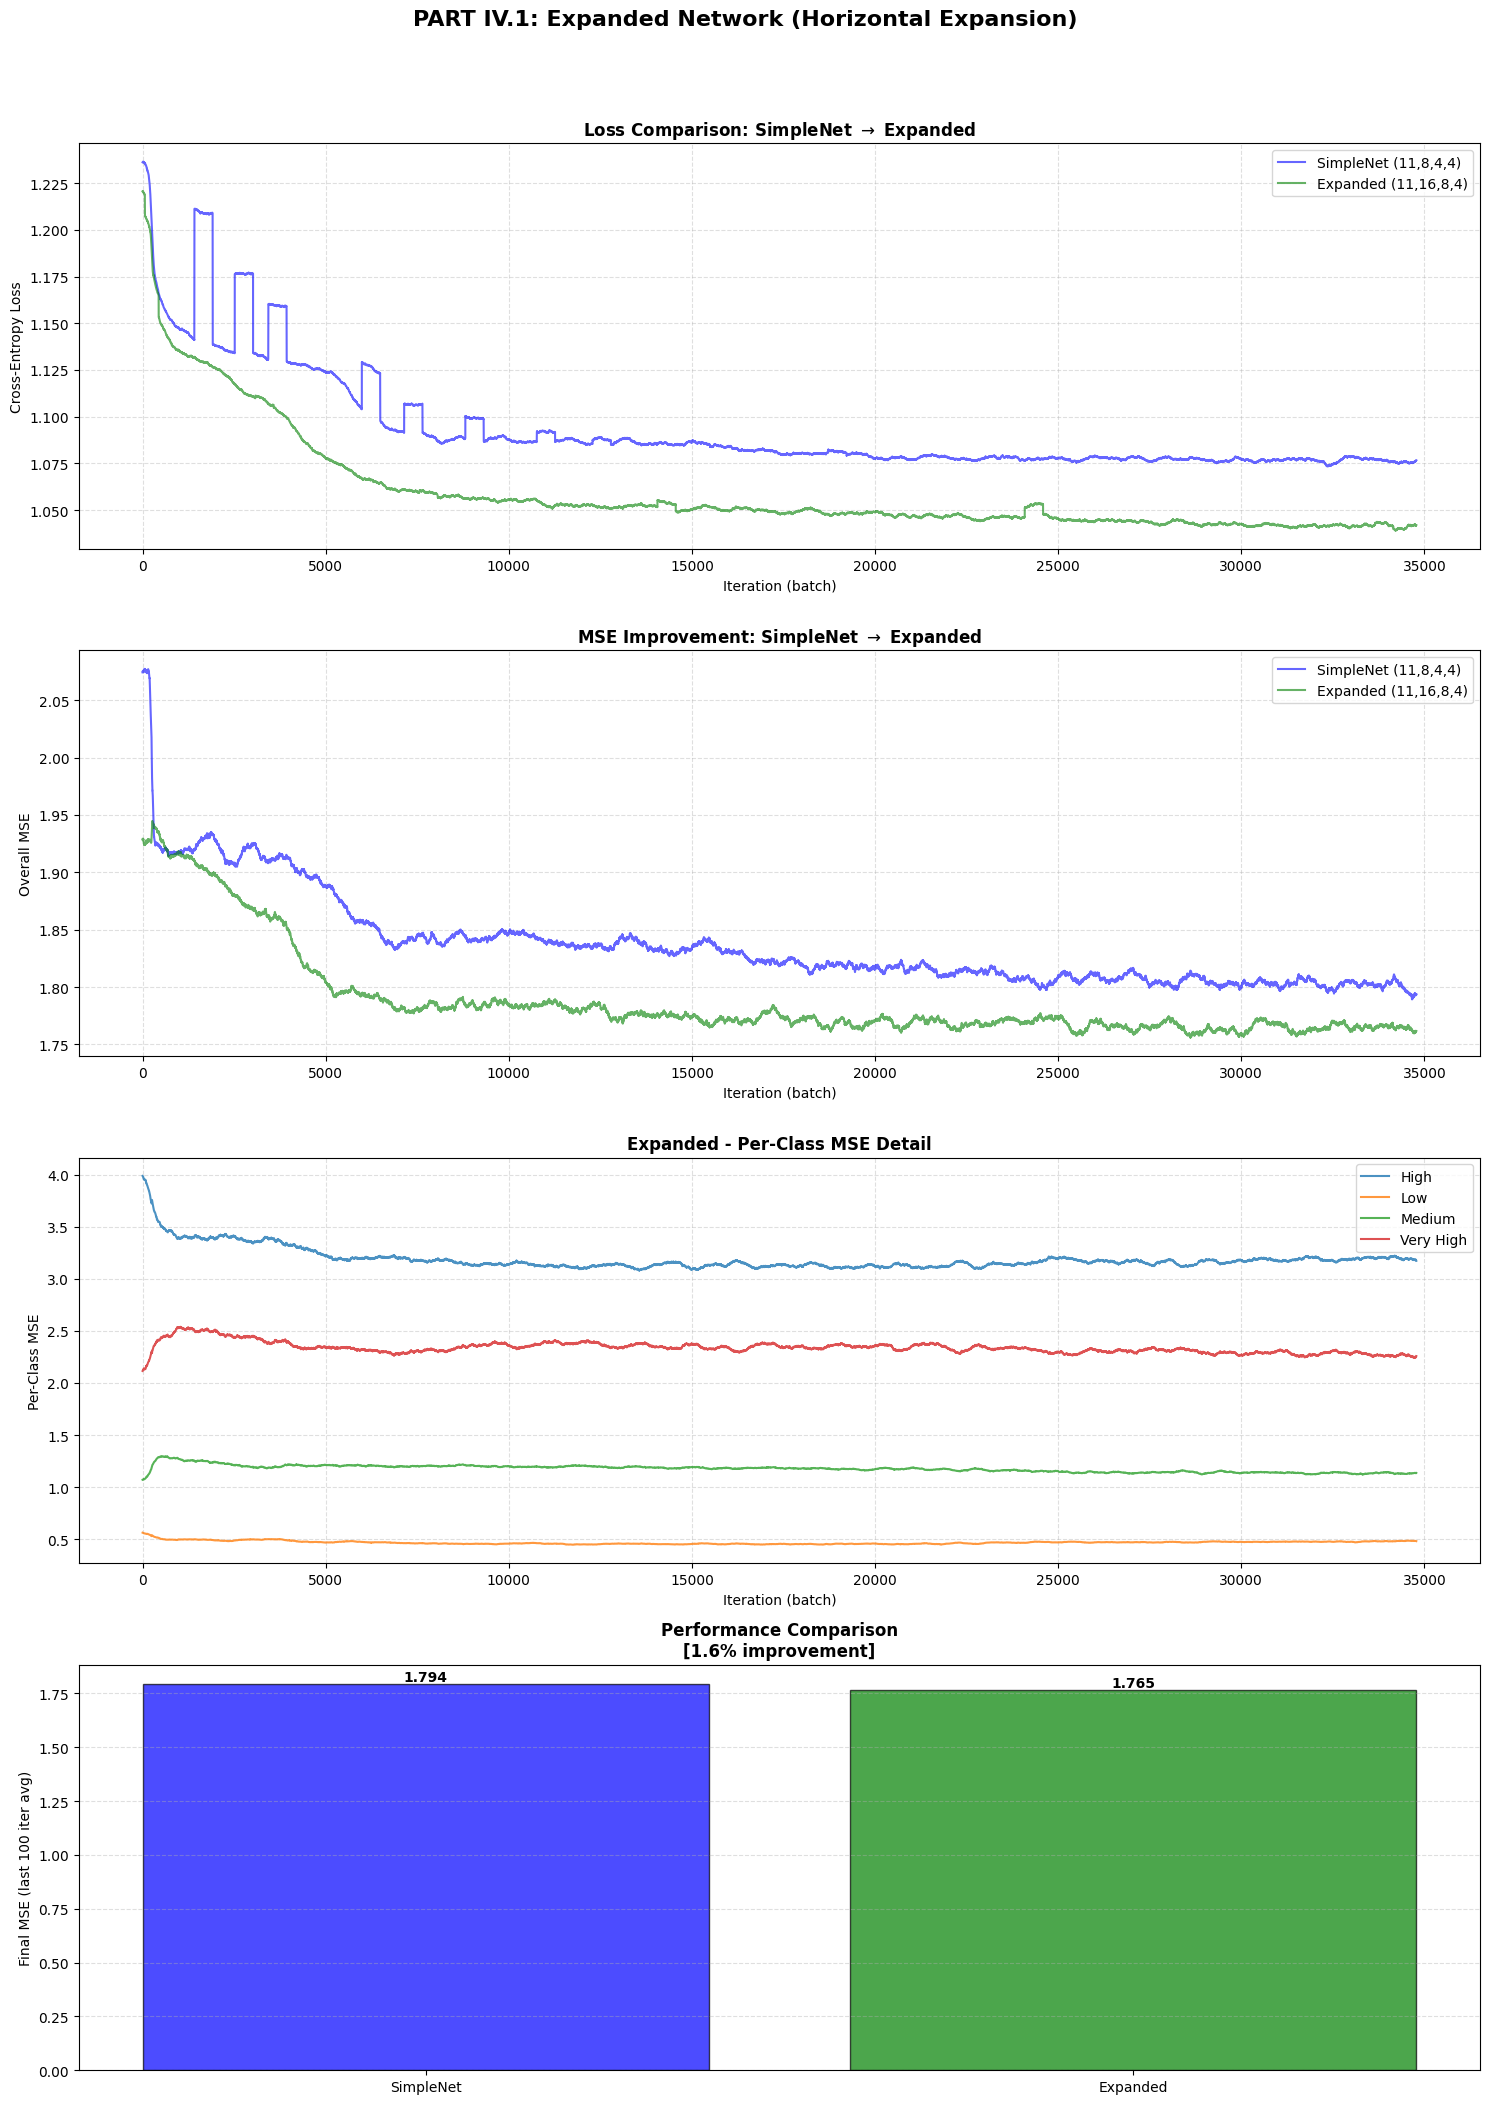

In [ ]:
# ============================================================================
# IMMEDIATE COMPARISON PLOT: SimpleNet vs Expanded
# ============================================================================
final_mse_exp = np.mean(expanded_iteration_data['mse_per_iteration'][-100:])
improvement_pct_exp = (final_mse_simple - final_mse_exp) / final_mse_simple * 100

print(f"📊 Expanded Final MSE: {final_mse_exp:.4f}")
print(f"✅ Improvement: {improvement_pct_exp:.1f}% better than SimpleNet")


fig, axes = plt.subplots(4, 1, figsize=(15, 20))


iterations_exp = np.arange(1, len(expanded_iteration_data['loss_per_iteration']) + 1)


# Compare Loss

# for index, value in enumerate(nn_comparison_list):
name, iterations, loss_per_iteration, mse_per_iteration = nn_comparison_plot_data(simplenet_iteration_data).values()
axes[0].plot(iterations, loss_per_iteration, label=name, color=nn_comparison_colors[0], alpha=0.6, linewidth=1.5)

name, iterations, loss_per_iteration, mse_per_iteration = nn_comparison_plot_data(expanded_iteration_data).values()
axes[0].plot(iterations, loss_per_iteration, label=name, color=nn_comparison_colors[1], alpha=0.6, linewidth=1.5)

axes[0].set_xlabel("Iteration (batch)")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Loss Comparison: SimpleNet $\\to$ Expanded", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

    # Compare MSE
# for index, value in enumerate(nn_comparison_list):
name, iterations, loss_per_iteration, mse_per_iteration = nn_comparison_plot_data(simplenet_iteration_data).values()
axes[1].plot(iterations, mse_per_iteration, label=name, color=nn_comparison_colors[0], alpha=0.6, linewidth=1.5)

name, iterations, loss_per_iteration, mse_per_iteration = nn_comparison_plot_data(expanded_iteration_data).values()
axes[1].plot(iterations, mse_per_iteration, label=name, color=nn_comparison_colors[1], alpha=0.6, linewidth=1.5)



axes[1].set_xlabel("Iteration (batch)")
axes[1].set_ylabel("Overall MSE")
axes[1].set_title("MSE Improvement: SimpleNet $\\to$ Expanded", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# Expanded Per-Class MSE
per_class_exp = {cls: [] for cls in encoder.classes_}
for d in expanded_iteration_data['per_class_mse_per_iteration']:
    for cls_name in encoder.classes_:
        per_class_exp[cls_name].append(d[cls_name])

for cls_name in encoder.classes_:
    axes[2].plot(iterations_exp, uniform_filter1d(per_class_exp[cls_name], 500),
                    label=cls_name, alpha=0.8, linewidth=1.5)
axes[2].set_xlabel("Iteration (batch)")
axes[2].set_ylabel("Per-Class MSE")
axes[2].set_title("Expanded - Per-Class MSE Detail", fontweight='bold')
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.4)

# Bar chart comparison
bars = axes[3].bar(['SimpleNet', 'Expanded'],
                   [final_mse_simple, final_mse_exp],
                   color=['blue', 'green'], alpha=0.7, edgecolor='black')
axes[3].set_ylabel("Final MSE (last 100 iter avg)")
axes[3].set_title(f"Performance Comparison\n[{improvement_pct_exp:.1f}% improvement]",
                  fontweight='bold')
axes[3].grid(axis='y', linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

plt.suptitle("PART IV.1: Expanded Network (Horizontal Expansion)",
             fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout(rect=[0, 0, 1, 1.02]) # Adjusted rect for suptitle
# plt.savefig("02_expanded_vs_simplenet_1_4.png", dpi=150, bbox_inches='tight')

In [ ]:
avg_overall_mse_expanded = float(np.mean(fold_overall_mse_exp))
per_class_mse_df_expanded = pd.DataFrame(fold_per_class_mse_exp)
avg_per_class_mse_expanded = per_class_mse_df_expanded.mean()

# From initial CV / M-trials or recompute similarly
initial_overall_mse = float(mean_overall_mse[-1])  # from SimpleNet M-trials last epoch
initial_per_class_mse = pd.Series(
    {cls: mean_per_class_mse[cls][-1] for cls in encoder.classes_}
)

comparison = pd.DataFrame({
    "Initial_MSE": initial_per_class_mse,
    "Expanded_MSE": avg_per_class_mse_expanded
})

print("Overall MSE – Initial vs Expanded")
print(f"Initial (SimpleNet, last epoch mean): {initial_overall_mse:.4f}")
print(f"Expanded (10-fold CV mean):         {avg_overall_mse_expanded:.4f}")
comparison


Overall MSE – Initial vs Expanded
Initial (SimpleNet, last epoch mean): 1.8451
Expanded (10-fold CV mean):         1.7817


,Initial_MSE,Expanded_MSE
High,3.571427,3.286378
Low,0.529123,0.477635
Medium,1.184761,1.160374
Very High,2.113286,2.221938


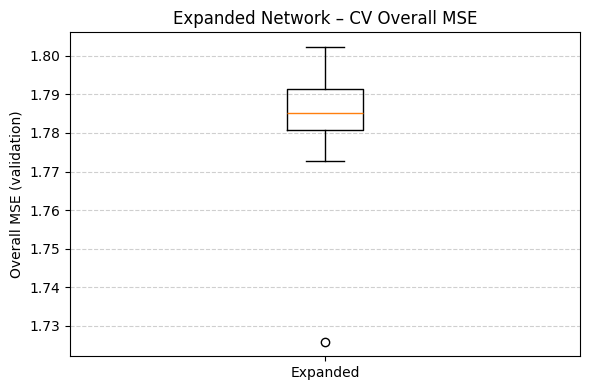

In [ ]:
# fold_overall_mse_exp: list of overall MSE values, length = num_folds

plt.figure(figsize=(6, 4))
plt.boxplot(fold_overall_mse_exp, vert=True, tick_labels=["Expanded"])
plt.ylabel("Overall MSE (validation)")
plt.title("Expanded Network – CV Overall MSE")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("expanded_cv_mse_boxplot.png", dpi=150)
plt.show()


In [ ]:

# Evaluation function WITH iteration tracking
def eval_model_once(model_cls, X_all, y_all, m_input, num_classes,
                                   model_name="Model", seed=123):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all
    )

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    X_te_t = torch.tensor(X_te, dtype=torch.float32).to(device)
    y_te_t = torch.tensor(y_te, dtype=torch.long).to(device)

    train_ds = torch.utils.data.TensorDataset(X_tr_t, y_tr_t)
    test_ds = torch.utils.data.TensorDataset(X_te_t, y_te_t)
    train_loader_loc = torch.utils.data.DataLoader(train_ds, batch_size=1024, shuffle=True)
    test_loader_loc = torch.utils.data.DataLoader(test_ds, batch_size=4096, shuffle=False)

    model = model_cls(m_input, num_classes).to(device)
    crit = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=0.005)

    # Iteration tracking
    iteration_data = {
        'loss_per_iteration': [],
        'mse_per_iteration': [],
        'per_class_mse_per_iteration': [],
        'model_name': model_name
    }

    n_epochs_loc = 10
    for ep in range(n_epochs_loc):
        model.train()
        for Xb, yb in train_loader_loc:
            opt.zero_grad()
            logits = model(Xb)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()

            # Track data
            iteration_data['loss_per_iteration'].append(loss.item())

            with torch.no_grad():
                preds = torch.argmax(logits, dim=1)
                errors = (preds - yb).float() ** 2
                batch_mse = errors.mean().item()
                iteration_data['mse_per_iteration'].append(batch_mse)

                class_mse_dict = {}
                for cls_idx, cls_name in enumerate(encoder.classes_):
                    mask = (yb == cls_idx)
                    if mask.any():
                        mse_cls = errors[mask].mean().item()
                    else:
                        mse_cls = float("nan")
                    class_mse_dict[cls_name] = mse_cls
                iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

    # Final evaluation
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for Xb, yb in test_loader_loc:
            logits = model(Xb)
            preds = torch.argmax(logits, dim=1)
            all_true.append(yb.cpu().numpy())
            all_pred.append(preds.cpu().numpy())

    all_true = np.concatenate(all_true)
    all_pred = np.concatenate(all_pred)
    errors = (all_pred - all_true) ** 2
    overall_mse = errors.mean()

    per_class_mse = {}
    for idx, cls_name in enumerate(encoder.classes_):
        mask = (all_true == idx)
        per_class_mse[cls_name] = errors[mask].mean() if mask.any() else np.nan

    return overall_mse, per_class_mse, iteration_data


In [ ]:
class DeepNet(nn.Module):
    """
    Deeper/wider network: (m, 32, 16, 8, C)
    for constructive growth experiment.
    """
    def __init__(self, m_star, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(m_star, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 8)
        self.fc4 = nn.Linear(8, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)


In [ ]:
# Train DeepNet

print("Training DeepNet...")
overall_mse_deep, per_class_mse_deep, deepnet_iteration_data = eval_model_once(
    DeepNet, X_pc_filtered, y_encoded, m_input, num_classes,
    model_name="DeepNet (11,32,16,8,4)", seed=123
)
print(f"DeepNet overall MSE: {overall_mse_deep}")

Training DeepNet...
DeepNet overall MSE: 1.7246437392267775


In [ ]:
# Cell [24.5] - Train DeepNet and compare with previous networks
print("="*80)
print("PART IV.2: DEEPNET - Deeper Architecture Experiment")
print("="*80)

print("Training DeepNet...")
model_deep = DeepNet(m_input, num_classes).to(device)
opt_deep = optim.Adam(model_deep.parameters(), lr=0.005)
crit_deep = nn.CrossEntropyLoss()

deepnet_iteration_data = {
    'loss_per_iteration': [],
    'mse_per_iteration': [],
    'per_class_mse_per_iteration': [],
    'model_name': 'DeepNet (11,32,16,8,4)'
}

# Use same train_loader
n_epochs_deep = 20
for epoch in range(n_epochs_deep):
    model_deep.train()
    for Xb, yb in train_loader:
        opt_deep.zero_grad()
        logits = model_deep(Xb)
        loss = crit_deep(logits, yb)
        loss.backward()
        opt_deep.step()

        deepnet_iteration_data['loss_per_iteration'].append(loss.item())

        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            errors = (preds - yb).float() ** 2
            batch_mse = errors.mean().item()
            deepnet_iteration_data['mse_per_iteration'].append(batch_mse)

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (yb == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls
            deepnet_iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

    print(f"  Epoch {epoch+1}/{n_epochs_deep}")

print("✓ DeepNet training complete\n")






PART IV.2: DEEPNET - Deeper Architecture Experiment
Training DeepNet...
  Epoch 1/20
  Epoch 2/20
  Epoch 3/20
  Epoch 4/20
  Epoch 5/20
  Epoch 6/20
  Epoch 7/20
  Epoch 8/20
  Epoch 9/20
  Epoch 10/20
  Epoch 11/20
  Epoch 12/20
  Epoch 13/20
  Epoch 14/20
  Epoch 15/20
  Epoch 16/20
  Epoch 17/20
  Epoch 18/20
  Epoch 19/20
  Epoch 20/20
✓ DeepNet training complete



📊 DeepNet Final MSE: 1.7293
✅ Total Improvement: 3.6% vs baseline


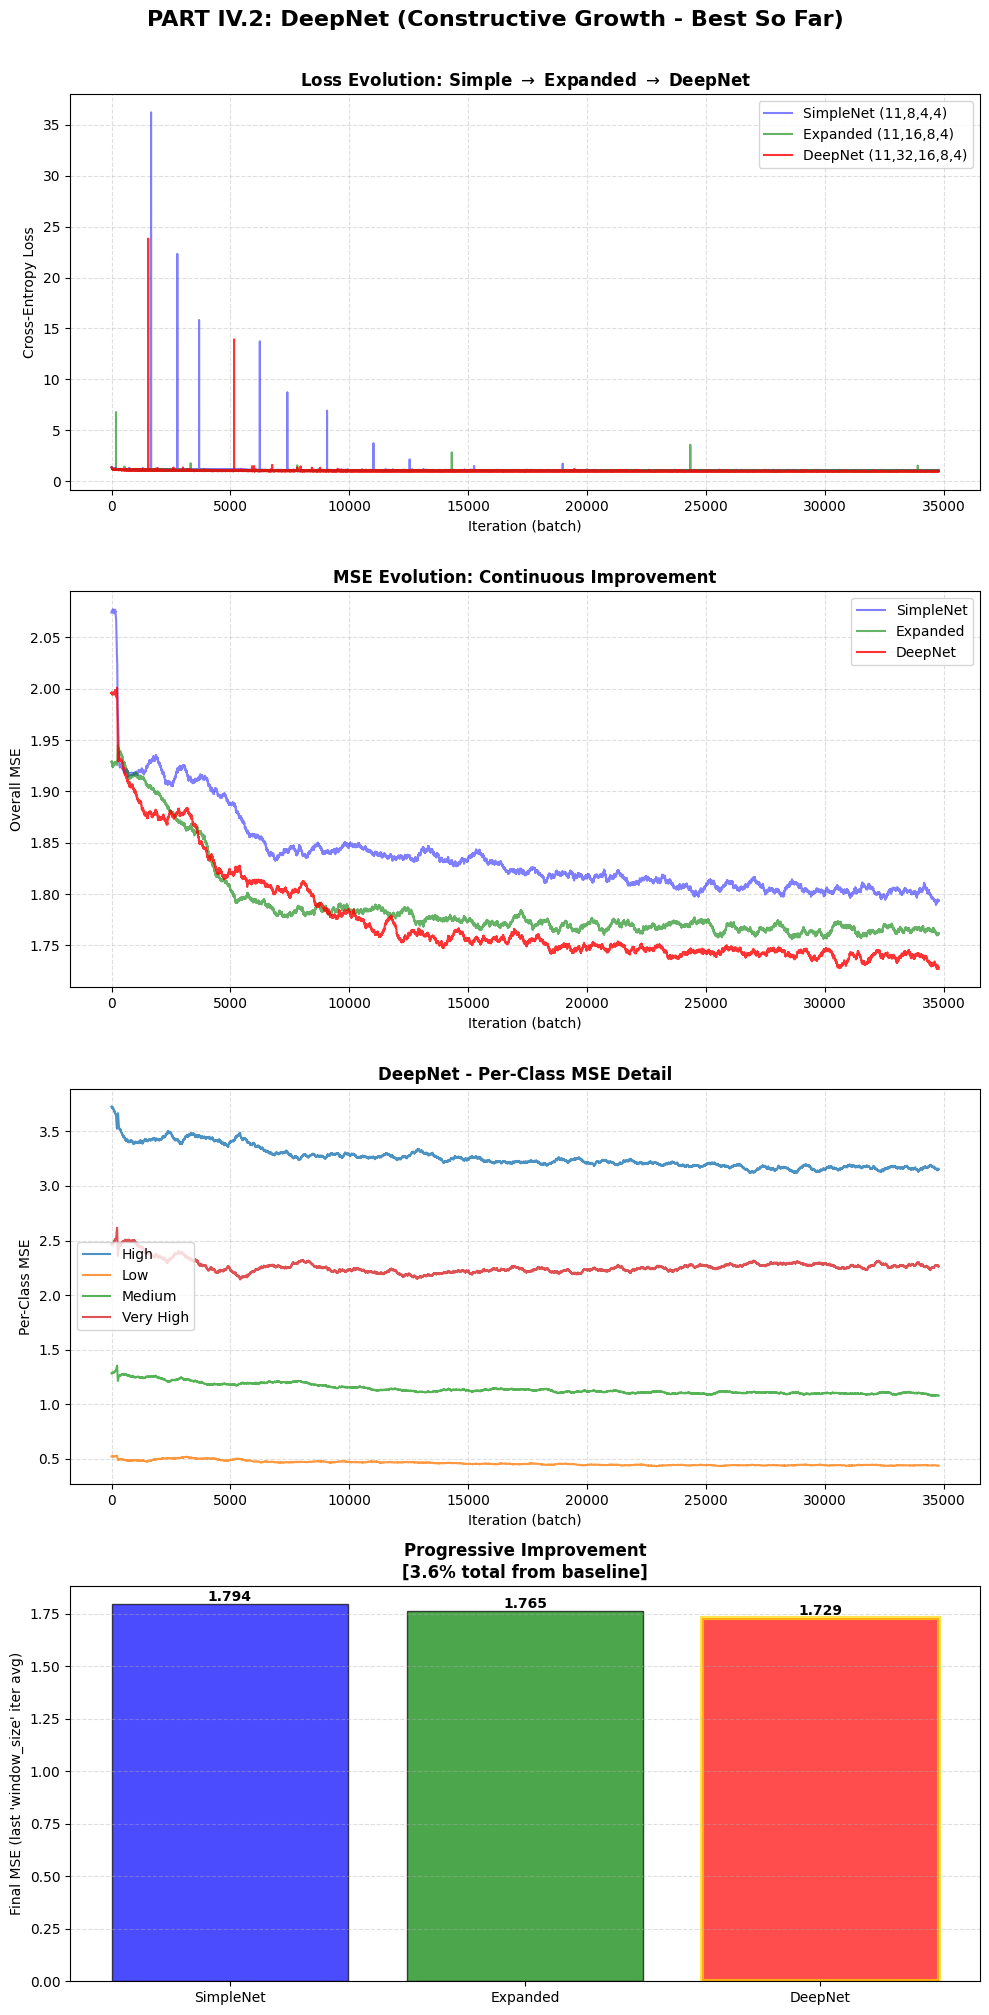

In [ ]:
# ============================================================================
# IMMEDIATE COMPARISON: SimpleNet vs Expanded vs DeepNet
# ============================================================================

final_mse_deep = np.mean(deepnet_iteration_data['mse_per_iteration'][-100:])
improvement_pct_deep = (final_mse_simple - final_mse_deep) / final_mse_simple * 100

fig, axes = plt.subplots(4, 1, figsize=(10, 20))

iterations_simple = np.arange(1, len(simplenet_iteration_data['loss_per_iteration']) + 1)
iterations_exp = np.arange(1, len(expanded_iteration_data['loss_per_iteration']) + 1)
iterations_deep = np.arange(1, len(deepnet_iteration_data['loss_per_iteration']) + 1)

# Loss progression
axes[0].plot(iterations_simple, simplenet_iteration_data['loss_per_iteration'],
             label='SimpleNet (11,8,4,4)', color='blue', alpha=0.5, linewidth=1.5)
axes[0].plot(iterations_exp, expanded_iteration_data['loss_per_iteration'],
             label='Expanded (11,16,8,4)', color='green', alpha=0.6, linewidth=1.5)
axes[0].plot(iterations_deep, deepnet_iteration_data['loss_per_iteration'],
             label='DeepNet (11,32,16,8,4)', color='red', alpha=0.8, linewidth=1.5)
axes[0].set_xlabel("Iteration (batch)")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Loss Evolution: Simple $\\to$ Expanded $\\to$ DeepNet", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# MSE progression
axes[1].plot(iterations_simple,uniform_filter1d(simplenet_iteration_data['mse_per_iteration'], size=window_size),
             label='SimpleNet', color='blue', alpha=0.5, linewidth=1.5)


axes[1].plot(iterations_exp, uniform_filter1d(expanded_iteration_data['mse_per_iteration'], size=window_size),
             label='Expanded', color='green', alpha=0.6, linewidth=1.5)

axes[1].plot(iterations_deep, uniform_filter1d(deepnet_iteration_data['mse_per_iteration'], size=window_size),
             label='DeepNet', color='red', alpha=0.8, linewidth=1.5)

axes[1].set_xlabel("Iteration (batch)")
axes[1].set_ylabel("Overall MSE")
axes[1].set_title("MSE Evolution: Continuous Improvement", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# DeepNet Per-Class
per_class_deep = {cls: [] for cls in encoder.classes_}
for d in deepnet_iteration_data['per_class_mse_per_iteration']:
    for cls_name in encoder.classes_:
        per_class_deep[cls_name].append(d[cls_name])

for cls_name in encoder.classes_:
    axes[2].plot(iterations_deep, uniform_filter1d(per_class_deep[cls_name], size=window_size),
                    label=cls_name, alpha=0.8, linewidth=1.5)
axes[2].set_xlabel("Iteration (batch)")
axes[2].set_ylabel("Per-Class MSE")
axes[2].set_title("DeepNet - Per-Class MSE Detail", fontweight='bold')
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.4)

# Bar chart: 3-way comparison
bars = axes[3].bar(['SimpleNet', 'Expanded', 'DeepNet'],
                   [final_mse_simple, final_mse_exp, final_mse_deep],
                   color=['blue', 'green', 'red'], alpha=0.7, edgecolor='black')
axes[3].set_ylabel("Final MSE (last 'window_size' iter avg)")
axes[3].set_title(f"Progressive Improvement\n[{improvement_pct_deep:.1f}% total from baseline]",
                  fontweight='bold')
axes[3].grid(axis='y', linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

# Highlight best
bars[2].set_edgecolor('gold')
bars[2].set_linewidth(3)

plt.suptitle("PART IV.2: DeepNet (Constructive Growth - Best So Far)",
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout(rect=[0, 0, 1, 1.0]) # Adjusted rect for suptitle with (4, 1)
plt.savefig("03_deepnet_constructive_growth_4_1.png", dpi=150, bbox_inches='tight')

print(f"📊 DeepNet Final MSE: {final_mse_deep:.4f}")
print(f"✅ Total Improvement: {improvement_pct_deep:.1f}% vs baseline")

In [ ]:
class PrunedNet(nn.Module):
    """
    Smaller network: (m, 8, 2, C)
    to mimic pruning / simplification.
    """
    def __init__(self, m_star, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(m_star, 8)
        self.fc2 = nn.Linear(8, 2)
        self.fc3 = nn.Linear(2, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# overall_mse_pruned, per_class_mse_pruned = eval_model_once(
#     PrunedNet, X_pc_filtered, y_encoded, m_input, num_classes, seed=123
# )
# print("PrunedNet overall MSE:", overall_mse_pruned)
# print("PrunedNet per-class MSE:", per_class_mse_pruned)


In [ ]:
# Cell [24.5] - Train PrunedNet and compare with previous networks
print("="*80)
print("PART IV.2: PRUNEDNET - Smaller Architecture Experiment")
print("="*80)

print("Training PrunedNet...")
model_pruned = PrunedNet(m_input, num_classes).to(device)
opt_pruned = optim.Adam(model_pruned.parameters(), lr=0.005)
crit_pruned = nn.CrossEntropyLoss()

prunednet_iteration_data = {
    'loss_per_iteration': [],
    'mse_per_iteration': [],
    'per_class_mse_per_iteration': [],
    'model_name': 'PrunedNet (m, 8, 2, C)'
}

# Use same train_loader
n_epochs_pruned = 20
for epoch in range(n_epochs_pruned):
    model_pruned.train()
    for Xb, yb in train_loader:
        opt_pruned.zero_grad()
        logits = model_pruned(Xb)
        loss = crit_pruned(logits, yb)
        loss.backward()
        opt_pruned.step()

        prunednet_iteration_data['loss_per_iteration'].append(loss.item())

        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            errors = (preds - yb).float() ** 2
            batch_mse = errors.mean().item()
            prunednet_iteration_data['mse_per_iteration'].append(batch_mse)

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (yb == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls
            prunednet_iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

    print(f"  Epoch {epoch+1}/{n_epochs_pruned}")

print("✓ PrunedNet training complete\n")



PART IV.2: PRUNEDNET - Smaller Architecture Experiment
Training PrunedNet...
  Epoch 1/20
  Epoch 2/20
  Epoch 3/20
  Epoch 4/20
  Epoch 5/20
  Epoch 6/20
  Epoch 7/20
  Epoch 8/20
  Epoch 9/20
  Epoch 10/20
  Epoch 11/20
  Epoch 12/20
  Epoch 13/20
  Epoch 14/20
  Epoch 15/20
  Epoch 16/20
  Epoch 17/20
  Epoch 18/20
  Epoch 19/20
  Epoch 20/20
✓ PrunedNet training complete



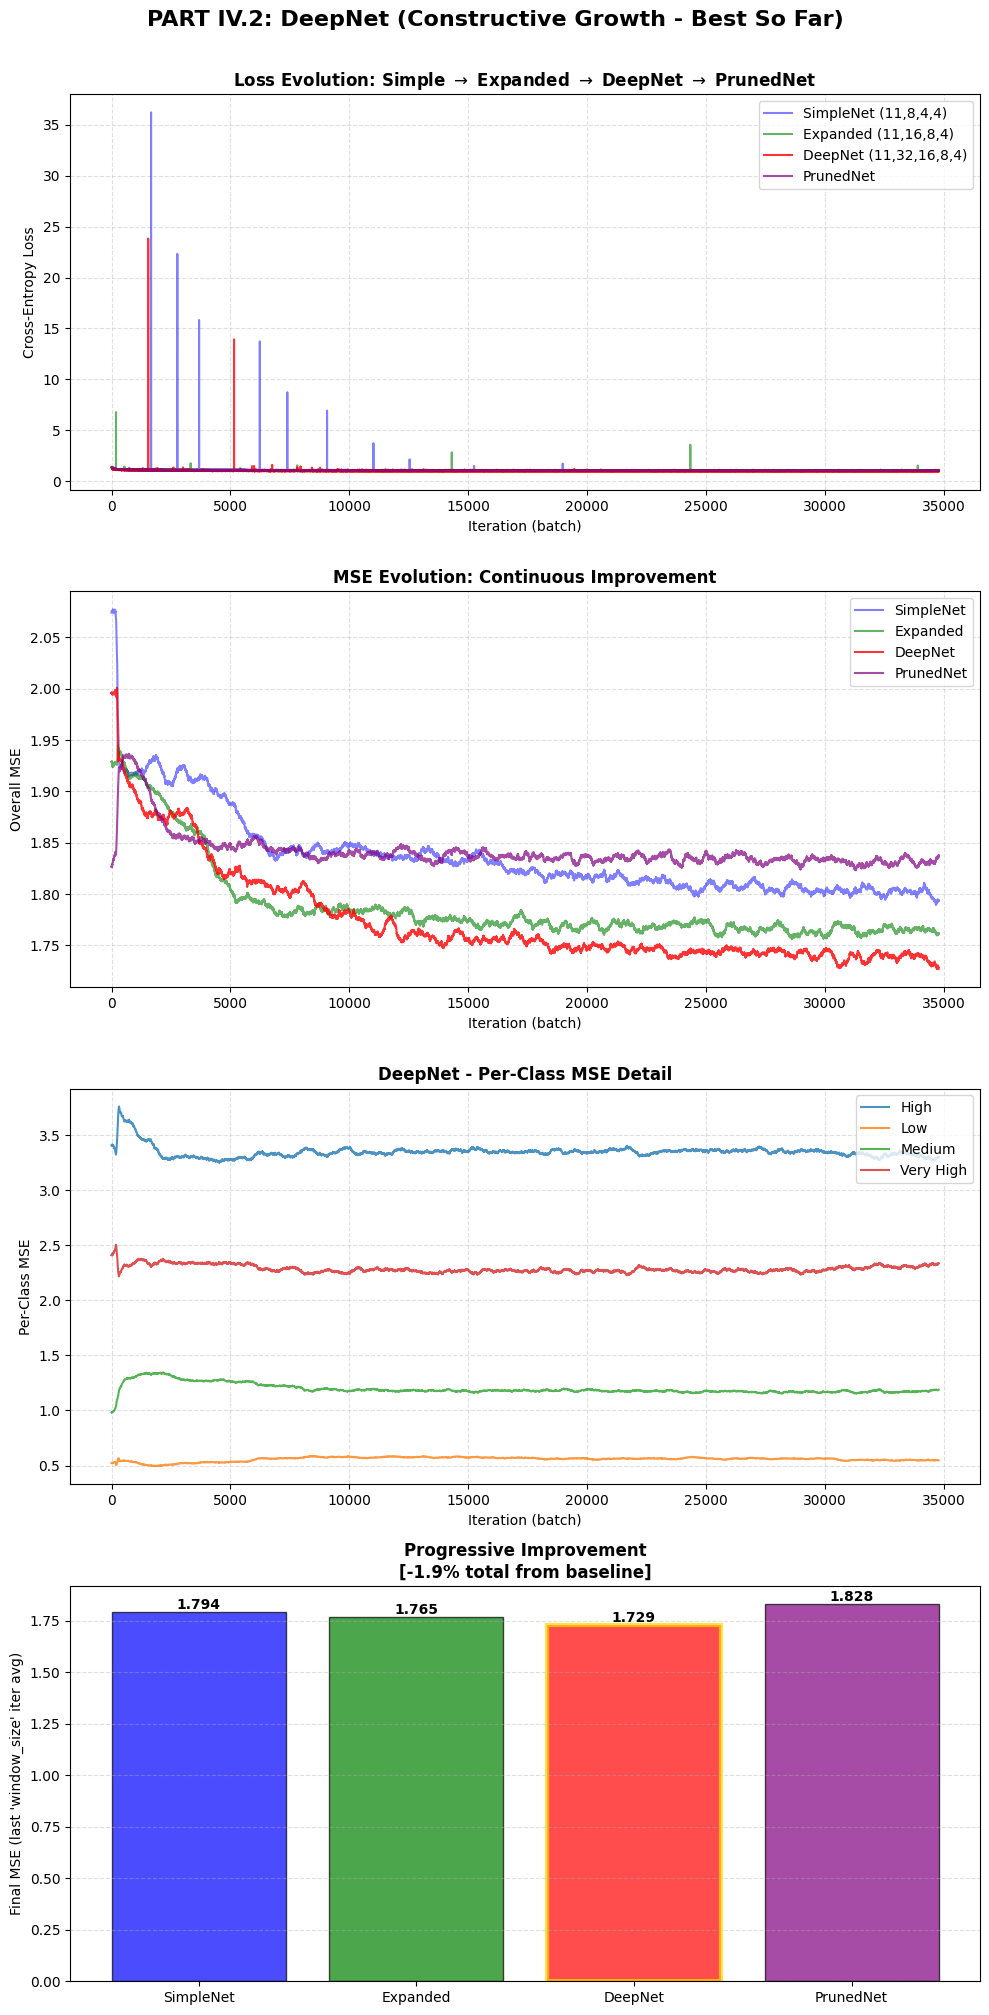

📊 DeepNet Final MSE: 1.8282
✅ Total Improvement: -1.9% vs baseline


In [ ]:
# ============================================================================
# IMMEDIATE COMPARISON: SimpleNet vs Expanded vs DeepNet vs PrunedNet
# ============================================================================
final_mse_pruned = np.mean(prunednet_iteration_data['mse_per_iteration'][-100:])
improvement_pct_pruned = (final_mse_simple - final_mse_pruned) / final_mse_simple * 100

fig, axes = plt.subplots(4, 1, figsize=(10, 20))

iterations_simple = np.arange(1, len(simplenet_iteration_data['loss_per_iteration']) + 1)
iterations_exp = np.arange(1, len(expanded_iteration_data['loss_per_iteration']) + 1)
iterations_deep = np.arange(1, len(deepnet_iteration_data['loss_per_iteration']) + 1)
iterations_pruned = np.arange(1, len(prunednet_iteration_data['loss_per_iteration']) + 1)

# Loss progression
axes[0].plot(iterations_simple, simplenet_iteration_data['loss_per_iteration'],
             label='SimpleNet (11,8,4,4)', color='blue', alpha=0.5, linewidth=1.5)
axes[0].plot(iterations_exp, expanded_iteration_data['loss_per_iteration'],
             label='Expanded (11,16,8,4)', color='green', alpha=0.6, linewidth=1.5)
axes[0].plot(iterations_deep, deepnet_iteration_data['loss_per_iteration'],
             label='DeepNet (11,32,16,8,4)', color='red', alpha=0.8, linewidth=1.5)
axes[0].plot(iterations_pruned, prunednet_iteration_data['loss_per_iteration'],
             label='PrunedNet', color='purple', alpha=0.7, linewidth=1.5)
axes[0].set_xlabel("Iteration (batch)")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Loss Evolution: Simple $\\to$ Expanded $\\to$ DeepNet $\\to$ PrunedNet", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# MSE progression
axes[1].plot(iterations_simple,uniform_filter1d(simplenet_iteration_data['mse_per_iteration'], size=window_size),
             label='SimpleNet', color='blue', alpha=0.5, linewidth=1.5)


axes[1].plot(iterations_exp, uniform_filter1d(expanded_iteration_data['mse_per_iteration'], size=window_size),
             label='Expanded', color='green', alpha=0.6, linewidth=1.5)

axes[1].plot(iterations_deep, uniform_filter1d(deepnet_iteration_data['mse_per_iteration'], size=window_size),
             label='DeepNet', color='red', alpha=0.8, linewidth=1.5)

axes[1].plot(iterations_pruned, uniform_filter1d(prunednet_iteration_data['mse_per_iteration'], size=window_size),
             label='PrunedNet', color='purple', alpha=0.7, linewidth=1.5)

axes[1].set_xlabel("Iteration (batch)")
axes[1].set_ylabel("Overall MSE")
axes[1].set_title("MSE Evolution: Continuous Improvement", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# DeepNet Per-Class
per_class_pruned = {cls: [] for cls in encoder.classes_}
for d in prunednet_iteration_data['per_class_mse_per_iteration']:
    for cls_name in encoder.classes_:
        per_class_pruned[cls_name].append(d[cls_name])

for cls_name in encoder.classes_:
    axes[2].plot(iterations_pruned, uniform_filter1d(per_class_pruned[cls_name], size=window_size),
                    label=cls_name, alpha=0.8, linewidth=1.5)
axes[2].set_xlabel("Iteration (batch)")
axes[2].set_ylabel("Per-Class MSE")
axes[2].set_title("DeepNet - Per-Class MSE Detail", fontweight='bold')
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.4)

# Bar chart: 3-way comparison
bars = axes[3].bar(['SimpleNet', 'Expanded', 'DeepNet', 'PrunedNet'],
                   [final_mse_simple, final_mse_exp, final_mse_deep, final_mse_pruned],
                   color=['blue', 'green', 'red', 'purple'], alpha=0.7, edgecolor='black')
axes[3].set_ylabel("Final MSE (last 'window_size' iter avg)")
axes[3].set_title(f"Progressive Improvement\n[{improvement_pct_pruned:.1f}% total from baseline]",
                  fontweight='bold')
axes[3].grid(axis='y', linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

# Highlight best
bars[2].set_edgecolor('gold')
bars[2].set_linewidth(3)

plt.suptitle("PART IV.2: DeepNet (Constructive Growth - Best So Far)",
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout(rect=[0, 0, 1, 1.0]) # Adjusted rect for suptitle with (4, 1)
plt.show()

print(f"📊 DeepNet Final MSE: {final_mse_pruned:.4f}")
print(f"✅ Total Improvement: {improvement_pct_pruned:.1f}% vs baseline")

In [ ]:
class ExpandedDropoutNet(nn.Module):
    """
    Fine-tuned network with dropout regularization:
    (m, 16, 8, C) + dropout.
    """
    def __init__(self, m_star, num_classes, p_drop=0.3):
        super().__init__()
        self.fc1 = nn.Linear(m_star, 16)
        self.fc2 = nn.Linear(16, 8)
        self.fc3 = nn.Linear(8, num_classes)
        self.dropout = nn.Dropout(p_drop)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)


In [ ]:
# Cell [24.5] - Train ExpandedDropoutNet and compare with previous networks
print("="*80)
print("PART IV.2: ExpandedDropoutNet (Constructive Growth with Dropout)")
print("="*80)

print("Training ExpandedDropoutNet...")
model_dropout = ExpandedDropoutNet(m_input, num_classes).to(device)
opt_dropout = optim.Adam(model_dropout.parameters(), lr=0.005)
crit_dropout = nn.CrossEntropyLoss()

dropoutnet_iteration_data = {
    'loss_per_iteration': [],
    'mse_per_iteration': [],
    'per_class_mse_per_iteration': [],
    'model_name': 'ExpandedDropoutNet (m,16,8,C, dropout)'
}

# Use same train_loader
n_epochs_dropout = 20
for epoch in range(n_epochs_dropout):
    model_dropout.train()
    for Xb, yb in train_loader:
        opt_dropout.zero_grad()
        logits = model_dropout(Xb)
        loss = crit_dropout(logits, yb)
        loss.backward()
        opt_dropout.step()

        dropoutnet_iteration_data['loss_per_iteration'].append(loss.item())

        with torch.no_grad():
            preds = torch.argmax(logits, dim=1)
            errors = (preds - yb).float() ** 2
            batch_mse = errors.mean().item()
            dropoutnet_iteration_data['mse_per_iteration'].append(batch_mse)

            class_mse_dict = {}
            for cls_idx, cls_name in enumerate(encoder.classes_):
                mask = (yb == cls_idx)
                if mask.any():
                    mse_cls = errors[mask].mean().item()
                else:
                    mse_cls = float("nan")
                class_mse_dict[cls_name] = mse_cls
            dropoutnet_iteration_data['per_class_mse_per_iteration'].append(class_mse_dict)

    print(f"  Epoch {epoch+1}/{n_epochs_dropout}")

print("✓ ExpandedDropoutNet training complete\n")



PART IV.2: ExpandedDropoutNet (Constructive Growth with Dropout)
Training ExpandedDropoutNet...
  Epoch 1/20
  Epoch 2/20
  Epoch 3/20
  Epoch 4/20
  Epoch 5/20
  Epoch 6/20
  Epoch 7/20
  Epoch 8/20
  Epoch 9/20
  Epoch 10/20
  Epoch 11/20
  Epoch 12/20
  Epoch 13/20
  Epoch 14/20
  Epoch 15/20
  Epoch 16/20
  Epoch 17/20
  Epoch 18/20
  Epoch 19/20
  Epoch 20/20
✓ ExpandedDropoutNet training complete



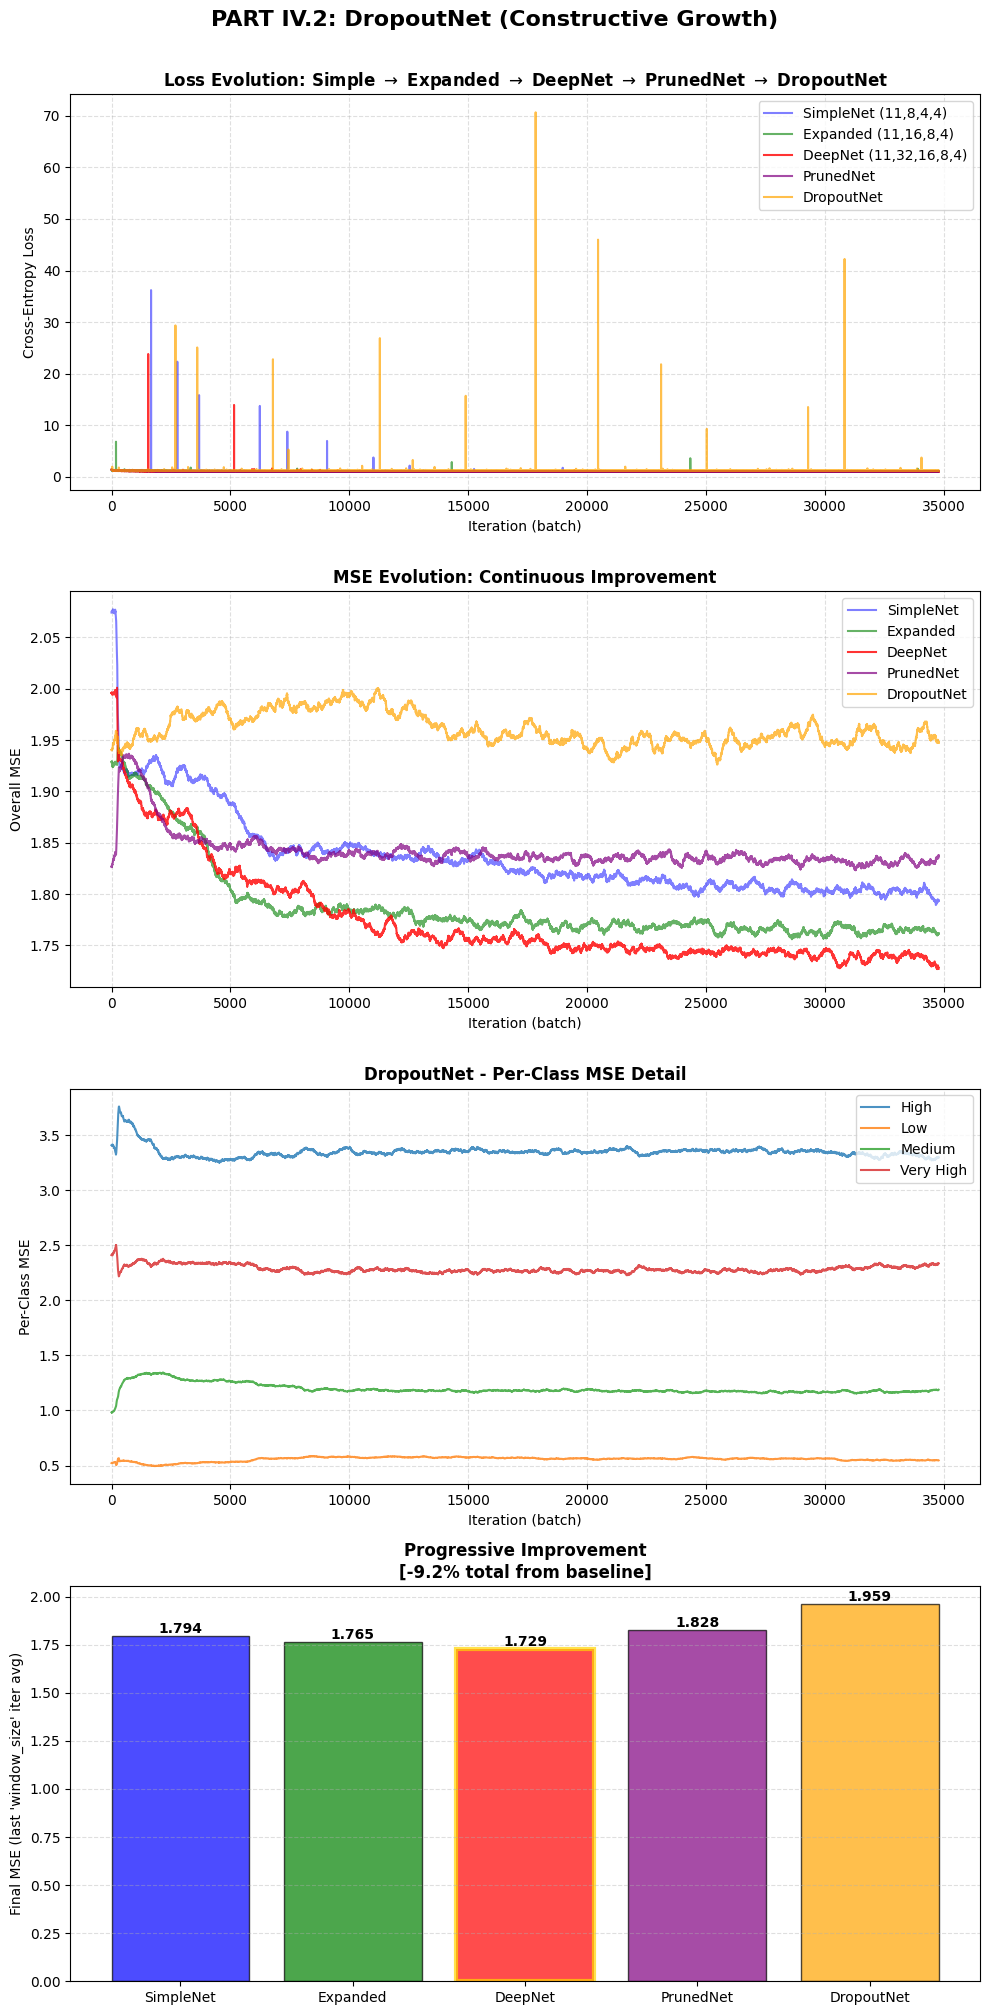

📊 DropoutNet Final MSE: 1.9593
✅ Total Improvement: -9.2% vs baseline


In [ ]:
# ============================================================================
# IMMEDIATE COMPARISON: SimpleNet vs Expanded vs DeepNet vs PrunedNet vs ExpandedDropoutNet
# ============================================================================

final_mse_dropout = np.mean(dropoutnet_iteration_data['mse_per_iteration'][-100:])
improvement_pct_dropout = (final_mse_simple - final_mse_dropout) / final_mse_simple * 100

fig, axes = plt.subplots(4, 1, figsize=(10, 20))

iterations_simple = np.arange(1, len(simplenet_iteration_data['loss_per_iteration']) + 1)
iterations_exp = np.arange(1, len(expanded_iteration_data['loss_per_iteration']) + 1)
iterations_deep = np.arange(1, len(deepnet_iteration_data['loss_per_iteration']) + 1)
iterations_pruned = np.arange(1, len(prunednet_iteration_data['loss_per_iteration']) + 1)

# Loss progression
axes[0].plot(iterations_simple, simplenet_iteration_data['loss_per_iteration'],
             label='SimpleNet (11,8,4,4)', color='blue', alpha=0.5, linewidth=1.5)
axes[0].plot(iterations_exp, expanded_iteration_data['loss_per_iteration'],
             label='Expanded (11,16,8,4)', color='green', alpha=0.6, linewidth=1.5)
axes[0].plot(iterations_deep, deepnet_iteration_data['loss_per_iteration'],
             label='DeepNet (11,32,16,8,4)', color='red', alpha=0.8, linewidth=1.5)
axes[0].plot(iterations_pruned, prunednet_iteration_data['loss_per_iteration'],
             label='PrunedNet', color='purple', alpha=0.7, linewidth=1.5)
axes[0].plot(iterations_pruned, dropoutnet_iteration_data['loss_per_iteration'],
             label='DropoutNet', color='orange', alpha=0.7, linewidth=1.5)
axes[0].set_xlabel("Iteration (batch)")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Loss Evolution: Simple $\\to$ Expanded $\\to$ DeepNet $\\to$ PrunedNet $\\to$ DropoutNet", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# MSE progression
axes[1].plot(iterations_simple,uniform_filter1d(simplenet_iteration_data['mse_per_iteration'], size=window_size),
             label='SimpleNet', color='blue', alpha=0.5, linewidth=1.5)


axes[1].plot(iterations_exp, uniform_filter1d(expanded_iteration_data['mse_per_iteration'], size=window_size),
             label='Expanded', color='green', alpha=0.6, linewidth=1.5)

axes[1].plot(iterations_deep, uniform_filter1d(deepnet_iteration_data['mse_per_iteration'], size=window_size),
             label='DeepNet', color='red', alpha=0.8, linewidth=1.5)

axes[1].plot(iterations_pruned, uniform_filter1d(prunednet_iteration_data['mse_per_iteration'], size=window_size),
             label='PrunedNet', color='purple', alpha=0.7, linewidth=1.5)

axes[1].plot(iterations_pruned, uniform_filter1d(dropoutnet_iteration_data['mse_per_iteration'], size=window_size),
             label='DropoutNet', color='orange', alpha=0.7, linewidth=1.5)


axes[1].set_xlabel("Iteration (batch)")
axes[1].set_ylabel("Overall MSE")
axes[1].set_title("MSE Evolution: Continuous Improvement", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# DropoutNet Per-Class
per_class_dropout = {cls: [] for cls in encoder.classes_}
for d in dropoutnet_iteration_data['per_class_mse_per_iteration']:
    for cls_name in encoder.classes_:
        per_class_dropout[cls_name].append(d[cls_name])

for cls_name in encoder.classes_:
    axes[2].plot(iterations_pruned, uniform_filter1d(per_class_pruned[cls_name], size=window_size),
                    label=cls_name, alpha=0.8, linewidth=1.5)
axes[2].set_xlabel("Iteration (batch)")
axes[2].set_ylabel("Per-Class MSE")
axes[2].set_title("DropoutNet - Per-Class MSE Detail", fontweight='bold')
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.4)

# Bar chart: 3-way comparison
bars = axes[3].bar(['SimpleNet', 'Expanded', 'DeepNet', 'PrunedNet', 'DropoutNet'],
                   [final_mse_simple, final_mse_exp, final_mse_deep, final_mse_pruned, final_mse_dropout],
                   color=['blue', 'green', 'red', 'purple', 'orange'], alpha=0.7, edgecolor='black')
axes[3].set_ylabel("Final MSE (last 'window_size' iter avg)")
axes[3].set_title(f"Progressive Improvement\n[{improvement_pct_dropout:.1f}% total from baseline]",
                  fontweight='bold')
axes[3].grid(axis='y', linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

# Highlight best
bars[2].set_edgecolor('gold')
bars[2].set_linewidth(3)

plt.suptitle("PART IV.2: DropoutNet (Constructive Growth)",
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout(rect=[0, 0, 1, 1.0]) # Adjusted rect for suptitle with (4, 1)
plt.show()

print(f"📊 DropoutNet Final MSE: {final_mse_dropout:.4f}")
print(f"✅ Total Improvement: {improvement_pct_dropout:.1f}% vs baseline")


